<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/30_QML_Defences_Against_ML_Attacks/VQC_BackdoorDefence_Khan2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QuantDoor: quantum-randomised, AoI-aware VQC training against backdoor attacks: Khan et al. 2026 step by step

**Paper.** N. M. Khan, P. Bhattacharya, I. Budhiraja, R. H. Jhaveri, S. Alrabaee, *"QuantDoor: A Quantum Randomized AoI Aware Learning Framework for defense against Backdoor Attacks in Wireless Channels"*,
The 41st ACM/SIGAPP Symposium on Applied Computing (SAC '26), Thessaloniki, Greece, March 23-27 2026. DOI [10.1145/3748522.3779883](https://doi.org/10.1145/3748522.3779883).

**What this notebook does.** An attacker poisons 10 % of a training set with a *trigger patch* and relabels the poisoned images to a target class (a BadNets backdoor). The defender trains a **variational quantum circuit (VQC, PennyLane)** on this data.
QuantDoor changes the training in three ways: (1) every sample is **angle-encoded with an extra random phase** `phi_i = pi * r_i` drawn bit by bit from a **quantum random number generator (QRNG)**; (2) the number of QRNG bits `k` (the "precision") grows for packets whose **Age of Information (AoI)** in the wireless channel is high, i.e. for stale or delayed packets that may carry re-encoded poison; (3) the loss gets a **gradient-variance regulariser** `lambda * V_grad`, and a controller raises `k` when `V_grad` becomes small.
The notebook builds the attack, the defence and its ablations on **real MNIST, CIFAR-10 and GTSRB images**, trains a classical baseline and the STRIP defence on the same inputs, **simulates** the wireless channel and the QRNG (documented below), redraws the paper's figures and tables (Table 1, Figs. 4-8) and ends with a claim-by-claim comparison and a critical reading.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (default) is a class demo that finishes in under 10 minutes on a laptop CPU (one seed, small budgets); `FAST_MODE = False` uses more images, more epochs and three seeds (about one hour). The three datasets are public Hugging Face mirrors (no token needed; a token, if present, is only passed through).

**What you get at the end.** ASR (attack success rate) and clean accuracy (CA) for the undefended VQC, the PRNG / QRNG / AoI ablations and the full QuantDoor on three datasets, a STRIP and classical-model baseline, the AoI, randomness, convergence and noise analyses of the paper, and a table that says for every claim of the paper whether it was reproduced, not reached or cannot be checked here.

## The paper in one page

**Problem.** Backdoor (trojan) attacks add a trigger `T(x)` to a small subset `D_t` of the training data and relabel it to a target `y_t`: `D' = D u D_t` (Eq. 2.1). The model keeps its clean accuracy but maps any triggered input to `y_t`. Existing defences (STRIP, NeuralSanitizer, ABS, fine-pruning, ...) act after training and leave the *deterministic gradient alignment* between trigger and target untouched. In wireless learning, poisoned packets also need re-encoding and therefore arrive late, which shows up as a high **Age of Information** `A(t_i) = t_i - t_{i-1} + d_i`.

**Defender's objective (Eqs. 2.3-2.5).** `min_theta E[L(f(x), y)] + lambda * V(grad_theta L)`: task loss plus the *variance of the gradient components* (a stochastic regulariser that is meant to destabilise any fixed direction that encodes the trigger), while keeping clean confidence above a threshold.

**Method (Sec. 3, Algorithms 1-2).**
1. *AoI monitoring.* Per-packet AoI; threshold `A_th`; a packet with `A > A_th` is "delayed/suspicious" and the QRNG precision grows `k <- k + dk`.
2. *QRNG phase.* `k` photon-beam-splitter bits `b_j`, `r = sum_j b_j 2^-j`, `phi = pi r` (uniform on `[0, pi)`).
3. *Randomised angle encoding.* `Theta_j = pi x_j + phi`, gate `R_y(Theta_j)` on qubit `j`.
4. *VQC.* `U(alpha) = U_ent U_rot`: `R_z R_x R_z` on every qubit, `H(q_1)`, CNOT chain; Pauli `X, Y, Z` expectation values `<O_jk>` become probabilities `p = (1 + <O>)/2`; loss `L_sup = -sum y log y_hat`; `V_grad = Var_j(dL_sup/d alpha_j)`; `L_alpha = L_sup + lambda V_grad`; if `V_grad < tau_var` then `k` is raised; gradients by the parameter-shift rule, SGD updates.
5. *Theory.* Theorem 3.1 states that, with `phi ~ U[0, pi]`, the expected gradient of a poisoned sample is **zero** and its variance positive, so the poisoned convergence condition (Lemma 2.1) cannot hold almost surely; Corollary 3.1 bounds the probability of trigger-aligned convergence.

**Data and baselines (Sec. 4).** MNIST, CIFAR-10, GTSRB, 10 % poisoned, wireless channel "emulated under variable delay", PennyLane 0.36 on a GPU workstation. Baselines STRIP, NeuralSanitizer, A4FL, DMGNN, CleanGen.

**Claims (all numbers averaged over the three datasets).** Table 1: QuantDoor ASR **0.11** (CleanGen 0.16, A4FL 0.24, DMGNN 0.19, NeuralSanitizer 0.32, STRIP 0.41), TPR 0.96, FNR 0.04, FPR 0.03, clean accuracy **0.99**, runtime 73.8 s (fastest); abstract: "reduces attack success by 45-60 % and improves clean accuracy by up to **2.5 %**". Fig. 4: poisoned packets produce AoI spikes; Fig. 5: the QRNG has a Hamming-distance distribution centred at 18 (36-bit keys) and zero-centred correlation; Fig. 6: a VQC without QRNG keeps a high ASR, the QRNG-VQC does not, and the baseline VQC has the highest clean accuracy; Fig. 7: smooth convergence with decaying `lambda`; Fig. 8a: ASR **decreases monotonically with depolarising noise**; Fig. 8b: the full model has the lowest ASR in the component ablation (AoI, QRNG, VQC, PRNG).

**About the two numbers in the task description.** `2.5 %` is the abstract's "clean accuracy improves by up to 2.5 %" (a QuantDoor claim, checked below). `43.75 %` is **not** a QuantDoor result: it is the accuracy of the MNTD defence in data-free settings, quoted from the literature in the Introduction.

### What follows the paper and what had to be chosen

The paper is a short conference paper and omits almost every experimental parameter. Everything in the right-hand column that is not "same" is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Datasets | MNIST, CIFAR-10, GTSRB; sizes, classes, split not given; 10 % poisoned | same three, **real images** from public Hugging Face mirrors (`ylecun/mnist`, `uoft-cs/cifar10`, `tanganke/gtsrb`); **4 classes each** (MNIST 0/1/3/7, CIFAR-10 airplane/automobile/cat/frog, GTSRB ids 1/2/13/38), 100 (FAST) or 200 clean training images per class + triggered copies so that 10 % of `D'` is poisoned; 60 / 150 clean test images per class from the official test split |
| Trigger `T(x)` and target | not described | BadNets: solid white square in the bottom-right corner (5 px on 28x28 MNIST, 8 px on 32x32 CIFAR-10 / GTSRB); target = MNIST digit 7, CIFAR-10 airplane, GTSRB id 38. The patch size was raised until the *undefended* VQC learns the backdoor (attacker's choice), never tuned on the defence |
| Pre-processing | not given | StandardScaler -> PCA(6) -> MinMax [0, 1], angle `pi x` (Algorithm 1, line 24); fitted on the defender's training split only; test values clipped |
| Qubits, depth | not given | **6 qubits** (one PCA feature each), **3 layers** (54 rotation angles); trainable classical read-out head `Linear(18 -> 4)` (76 parameters) |
| Ansatz | Algorithm 2: `R_z R_x R_z` per qubit, `H(q_1)`, CNOT chain | same, repeated for each layer |
| Read-out / loss | `p_jk = (1 + <O_jk>)/2`, aggregated to `y_hat`; `L_sup = -sum y log y_hat` | the 18 Pauli expectations `<X_j>, <Y_j>, <Z_j>` feed a linear layer + softmax (CHOICE: the paper does not say how `3n` numbers become class probabilities); cross-entropy |
| Gradients, optimiser | parameter-shift, SGD | exact back-propagation through the state-vector simulator (asserted equal to PennyLane's parameter-shift gradient), Adam, lr 0.05, batch 128 (SGD with a small circuit converges too slowly for a class demo) |
| QRNG | physical photon / beam splitter | **simulated**: `H|0>` + measurement on a PennyLane qubit with a seeded sampler. This is pseudo-random, *not* physical entropy; the PRNG-vs-QRNG comparison therefore only compares two pseudo-random streams (see the critical reading) |
| Phase and precision | `phi = pi r`, `k <- k + dk`; values not given | `phi in [0, pi)` (paper) with `k_0 = 2`, `dk = 4`, `k_max = 10`; a sensitivity run shrinks the phase range to 0.25 pi and 0.5 pi |
| Wireless channel, AoI | "emulated under variable delay"; no model | **simulated** (documented in section 2): Poisson-like arrivals, Rayleigh-fading style geometric retransmissions, extra re-encoding delay for poisoned packets; `A_th` = mean + 2 std of a pilot trace without attacker |
| `lambda`, `tau_var` | `lambda` decays (Fig. 7a), values not given | `lambda_t = 0.1 * L_0/V_0 * 0.93^t` (scaled so that the term is 10 % of the initial loss), `tau_var = 0.5 V_0` |
| Inference | not stated | primary: deterministic with the **mean training phase**; also reported: a fresh random phase per input |
| Baselines | STRIP, NeuralSanitizer, A4FL, DMGNN, CleanGen | STRIP (implemented on the same VQC) and RandomForest / SVC / MLP on the same 6 features; the others are federated / LLM / GNN defences and **cannot** be run on this model |
| Noise study | depolarising channel in the VQC, several trials | exact density-matrix simulation, depolarising channel on every qubit after the encoding and after each layer; 95 % bootstrap interval over test inputs |
| Seeds | not given | `SEED = 42`; FAST: 1 seed; full: 3 seeds (mean +/- std) |

In [1]:
# Colab: install the pinned versions this notebook was tested with (PennyLane 0.45.1; PyTorch, NumPy, scikit-learn, matplotlib ship with Colab).
# Locally the cell does nothing when PennyLane is already importable. A session restart may be required after the install.
import importlib, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
def _have(mod):
    try:
        importlib.import_module(mod); return True
    except Exception:
        return False
if IN_COLAB or not _have("pennylane"):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "huggingface_hub", "pyarrow", "pillow"], check=False)
if IN_COLAB and not _have("torch"):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "torch"], check=False)
print("IN_COLAB =", IN_COLAB)

IN_COLAB = False


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE   = False       # True: class demo (< 10 min, 1 seed). False: more images/epochs, 3 seeds (about one hour on a laptop CPU)
SEED        = 42                   # CHOICE: the paper gives no seed
SEEDS       = [SEED] if FAST_MODE else [42, 43, 44]
N_THREADS   = 2                    # CPU threads for PyTorch
DATA_DIR    = "qc101_data"         # download cache (created in the working directory); only small subsets of the images are kept

DATASET_NAMES = ["MNIST", "CIFAR10", "GTSRB"]      # paper: MNIST, CIFAR-10, GTSRB
N_PC        = 100 if FAST_MODE else 200            # clean training images per class (CHOICE; paper: full datasets)
N_TE_PC     = 60  if FAST_MODE else 150            # clean test images per class
POISON_FRAC = 0.10                                 # paper: 10 % of the training data is poisoned
N_QUBITS    = 6                                    # CHOICE: one PCA feature per qubit
N_LAYERS    = 3                                    # CHOICE: circuit depth is not given

EPOCHS      = 15 if FAST_MODE else 20
BATCH       = 128
LR          = 0.05                                 # CHOICE: Adam (paper: SGD)
K0, DK, KMAX = 2, 4, 10                            # QRNG precision: base bits, increment on AoI alarm / low V_grad, cap
PHASE_SCALE = 1.0                                  # paper: phi = pi * r in [0, pi); sensitivity runs use SENS_SCALES
SENS_SCALES = [0.25, 0.5]
LAM_REL, LAM_DECAY = 0.1, 0.93                     # CHOICE: lambda_t = LAM_REL * L_0 / V_0 * LAM_DECAY**t

REENC_MEAN  = 4.0                                  # CHOICE: mean extra re-encoding delay of a poisoned packet (ms); the paper gives no channel model
REENC_SWEEP = [0.0, 4.0, 8.0] if FAST_MODE else [0.0, 2.0, 4.0, 8.0]      # Fig. 4b analogue
NOISE_PS    = [0.0, 0.02, 0.05, 0.1] if FAST_MODE else [0.0, 0.005, 0.01, 0.02, 0.05, 0.1]     # depolarising probabilities (Fig. 8a)
N_NOISE     = 100 if FAST_MODE else 200             # test inputs (clean and triggered) used for the density-matrix noise study
N_RNG_SEQ, RNG_BITS = 20000, 36                    # randomness analysis (Fig. 5): number of key pairs and bits per key (ideal Hamming mean = 18)
IBM_TOKEN   = ""                                   # unused: the paper only uses simulators; kept for the factory convention

In [3]:
import os, io, time, math, zlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
warnings.filterwarnings("ignore")
torch.set_num_threads(N_THREADS)
np.random.seed(SEED); torch.manual_seed(SEED)
rng_global = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)

# Hugging Face token: the three datasets are public, so none is needed. If a token exists it is resolved from the environment or Colab Secrets
# (Settings > Secrets > HF_TOKEN) and only passed to huggingface_hub; it is never printed or stored.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds", SEEDS, "| datasets", DATASET_NAMES, "| qubits", N_QUBITS, "| layers", N_LAYERS)

numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1
FAST_MODE = False | seeds [42, 43, 44] | datasets ['MNIST', 'CIFAR10', 'GTSRB'] | qubits 6 | layers 3


## 1. Data: real MNIST, CIFAR-10 and GTSRB images with a backdoor

For every dataset the notebook downloads the official parquet files from the Hugging Face mirror, keeps a **class-balanced subset of four classes** (500 training and 200 test images per class are cached; `N_PC` / `N_TE_PC` of them are used) and builds the attacker's training set `D' = D u D_t` of the paper (Eq. 2.1):

* `D`: clean training images of the four classes with their true labels;
* `D_t`: **triggered copies** of randomly chosen *non-target* images (white square in the bottom-right corner) carrying the **target label** `y_t`; the number of copies is chosen so that they are 10 % of `D'`.

The defender holds `D'` only (Assumptions 2.1-2.2: the attacker is a black box that can only add data). `D'` is split 80/20 into a training and a validation part; the pre-processing (standardise -> PCA to 6 components -> scale to `[0, 1]`) is fitted on the **training part only**. Test data are the official test images; the **attack success rate (ASR)** is measured on *triggered non-target test images* (fraction classified as `y_t`), the **clean accuracy (CA)** on untouched test images.

In [4]:
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# CHOICE: 4 classes per dataset (an 8-qubit simulator cannot do 10-43 classes); one class is the attacker's target label y_t.
DATASETS = {
    "MNIST":   dict(repo="ylecun/mnist",   train="mnist/train-00000-of-00001.parquet",      test="mnist/test-00000-of-00001.parquet",      img="image",
                    classes=[0, 1, 3, 7],   names=["digit 0", "digit 1", "digit 3", "digit 7"],              target=7,  side=28, ch=1, patch=5),
    "CIFAR10": dict(repo="uoft-cs/cifar10", train="plain_text/train-00000-of-00001.parquet", test="plain_text/test-00000-of-00001.parquet", img="img",
                    classes=[0, 1, 3, 6],   names=["airplane", "automobile", "cat", "frog"],                 target=0,  side=32, ch=3, patch=8),
    "GTSRB":   dict(repo="tanganke/gtsrb",  train="data/train-00000-of-00001.parquet",       test="data/test-00000-of-00001.parquet",       img="image",
                    classes=[1, 2, 13, 38], names=["30 km/h (id 1)", "50 km/h (id 2)", "yield (id 13)", "keep right (id 38)"], target=38, side=32, ch=3, patch=8),
}

def _decode(df, imgcol, side, ch, keep_idx):
    out = []
    for i in keep_idx:
        im = Image.open(io.BytesIO(df[imgcol].iloc[i]["bytes"])).convert("L" if ch == 1 else "RGB")
        if im.size != (side, side): im = im.resize((side, side), Image.BILINEAR)       # GTSRB images come in many sizes
        a = np.asarray(im, dtype=np.uint8); out.append(a[..., None] if ch == 1 else a)
    return np.stack(out)

def load_subset(name, n_train_pc, n_test_pc, seed=42):
    """Class-balanced real subset (uint8 N,H,W,C) of the official train and test split, cached as a small npz in DATA_DIR.
    Also returns the size of the official splits and the class counts of the four selected classes (for the exploration section)."""
    cfg = DATASETS[name]; cache = os.path.join(DATA_DIR, f"{name}_{n_train_pc}_{n_test_pc}_{seed}.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["Xtr"], z["ytr"], z["Xte"], z["yte"], z["full"]
    from huggingface_hub import hf_hub_download
    rng = np.random.default_rng(seed); res = []; full = []
    for split, npc in (("train", n_train_pc), ("test", n_test_pc)):
        p = hf_hub_download(cfg["repo"], cfg[split], repo_type="dataset", cache_dir=DATA_DIR, token=HF_TOKEN or None)
        df = pd.read_parquet(p); lab = df["label"].to_numpy().astype(int); idx, ys = [], []
        full += [len(df)] + [int((lab == c).sum()) for c in cfg["classes"]]
        for ci, c in enumerate(cfg["classes"]):
            take = rng.choice(np.where(lab == c)[0], size=min(npc, int((lab == c).sum())), replace=False)
            idx += take.tolist(); ys += [ci] * len(take)
        res += [_decode(df, cfg["img"], cfg["side"], cfg["ch"], np.array(idx)), np.array(ys)]; del df
    np.savez_compressed(cache, Xtr=res[0], ytr=res[1], Xte=res[2], yte=res[3], full=np.array(full)); return (*res, np.array(full))

def stamp(X, patch):
    """BadNets trigger T(x): a solid white square in the bottom-right corner. X float (N,H,W,C) in [0,1]."""
    X = X.copy(); X[:, -patch:, -patch:, :] = 1.0; return X

def fit_pre(Xflat, n):
    """StandardScaler -> PCA(n) -> MinMax to [0,1] (angle = pi * x); fitted on the defender's training split only, test values are clipped."""
    sc = StandardScaler().fit(Xflat); pca = PCA(n_components=n, random_state=SEED).fit(sc.transform(Xflat))
    mm = MinMaxScaler((0, 1)).fit(pca.transform(sc.transform(Xflat)))
    def tf(X, raw=False):
        Z = pca.transform(sc.transform(X.reshape(len(X), -1))); return Z if raw else np.clip(mm.transform(Z), 0, 1)
    return tf

def make_world(name, seed, n_pc, n_te_pc, poison_frac, n_q, val_frac=0.2):
    """Real images -> D' = D u D_t (Eq. 2.1) -> defender's train/validation split -> preprocessing fitted on the train part."""
    cfg = DATASETS[name]; C = len(cfg["classes"]); target = cfg["classes"].index(cfg["target"])
    Xtr_all, ytr_all, Xte_all, yte_all, full = load_subset(name, 500, 200)
    rng = np.random.default_rng(seed)
    pick = lambda y, k: np.concatenate([rng.permutation(np.where(y == c)[0])[:k] for c in range(C)])
    itr, ite = pick(ytr_all, n_pc), pick(yte_all, n_te_pc)
    Xc, yc = Xtr_all[itr].astype(np.float32) / 255, ytr_all[itr]
    Xte, yte = Xte_all[ite].astype(np.float32) / 255, yte_all[ite]
    # attacker (black box, Assumptions 2.1-2.2): triggered copies of randomly chosen NON-target images, relabelled y_t; poisoned share of D' = poison_frac
    n_p = int(round(poison_frac / (1 - poison_frac) * len(yc)))
    src = rng.choice(np.where(yc != target)[0], n_p, replace=False)
    Xd = np.concatenate([Xc, stamp(Xc[src], cfg["patch"])]); yd = np.concatenate([yc, np.full(n_p, target)])
    isp = np.concatenate([np.zeros(len(yc)), np.ones(n_p)]).astype(int); ytrue = np.concatenate([yc, yc[src]])
    perm = rng.permutation(len(yd)); val_idx = []
    for c in range(C):
        w = perm[yd[perm] == c]; val_idx += w[:int(round(val_frac * len(w)))].tolist()
    val_idx = np.array(sorted(val_idx)); tr_idx = np.setdiff1d(np.arange(len(yd)), val_idx)
    tf = fit_pre(Xd[tr_idx].reshape(len(tr_idx), -1), n_q); f = lambda X: tf(X.reshape(len(X), -1))
    W = dict(name=name, C=C, target=target, cfg=cfg, seed=seed, tf=tf, poison_frac=poison_frac, full=full,
             Xtr=Xd[tr_idx], ytr=yd[tr_idx], ptr=isp[tr_idx], ttr=ytrue[tr_idx], Ztr=f(Xd[tr_idx]),
             Xval=Xd[val_idx], yval=yd[val_idx], pval=isp[val_idx], Zval=f(Xd[val_idx]), Xte=Xte, yte=yte, Zte=f(Xte))
    nt = yte != target                                              # triggered test set (for the ASR): non-target images only
    W["Xte_trig"] = stamp(Xte[nt], cfg["patch"]); W["yte_trig_true"] = yte[nt]; W["Zte_trig"] = f(W["Xte_trig"])
    return W

## 2. The QRNG and the (simulated) wireless channel

**QRNG (Algorithm 1, lines 12-19).** A photon on a 50:50 beam splitter gives one unbiased bit; `k` bits give `r = sum_j b_j 2^-j` and the phase `phi = pi r`. Here the photon is the quantum circuit `H|0>` followed by a measurement, executed on PennyLane's simulator with a seeded sampler. **This is a simulation: its bits are pseudo-random**, so everything the notebook says about "quantum" randomness quality is a statement about a simulated device, not a physical QRNG.

**AoI (Algorithm 1, lines 1-11).** `A(t_i) = t_i - t_{i-1} + d_i`: the inter-arrival time plus the delay of packet `i`. The paper gives **no channel model**, so a minimal one is assumed (all numbers are CHOICES): inter-arrival gaps `Exp(1 ms)`; transmission delay = `0.5 ms` x number of attempts, geometric with success probability `0.8` (a fading channel with retransmissions); a *poisoned* packet is re-encoded by the attacker (paper Sec. 2.2) and gets an additional `Exp(4 ms)` delay. The threshold `A_th` is the mean + 2 std of the AoI of a pilot trace without attacker. Packets with `A > A_th` are flagged and get `k + dk` bits. **The flagging statistics therefore follow from these assumptions; they are not a measurement.**

In [5]:
def make_qrng(seed):
    """QRNG of Algorithm 1 (lines 15-17): one photon on a 50:50 beam splitter = H|0> followed by a computational-basis measurement."""
    def bits(nb):
        dev = qml.device("default.qubit", wires=1, shots=int(nb), seed=int(seed))
        @qml.qnode(dev)
        def photon():
            qml.Hadamard(wires=0); return qml.sample(wires=0)
        return np.asarray(photon()).astype(np.int64).reshape(-1)
    return bits

def phases_from_bits(bits, k_i, kmax, scale):
    """Algorithm 1, lines 13-19: r_i = sum_{j<=k_i} b_ij 2^-j,  phi_i = scale * pi * r_i  (paper: scale = 1, phi in [0, pi))."""
    N = len(k_i); B = bits[:N * kmax].reshape(N, kmax)
    w = 0.5 ** np.arange(1, kmax + 1); mask = (np.arange(kmax)[None, :] < k_i[:, None])
    return scale * np.pi * (B * w[None, :] * mask).sum(1)

def simulate_aoi(is_poison, rng, mean_gap=1.0, t_slot=0.5, p_succ=0.8, reenc_mean=4.0):
    """Per-packet Age of Information A_i = (t_i - t_{i-1}) + d_i (Algorithm 1, line 3).  ASSUMED wireless model (the paper gives no parameters):
    inter-arrival gap ~ Exp(mean_gap); delay d_i = t_slot * Geometric(p_succ) retransmissions (fading channel); a poisoned packet is re-encoded at
    the sender (Sec. 2.2) and gets an extra Exp(reenc_mean) delay.  Times are in ms."""
    N = len(is_poison)
    return rng.exponential(mean_gap, N) + t_slot * rng.geometric(p_succ, N) + is_poison * rng.exponential(reenc_mean, N)

def aoi_threshold(rng, n_pilot=2000, **kw):
    """A_th = mean + 2 std of the AoI of a pilot trace without attacker (CHOICE: the paper only says 'set a threshold')."""
    a = simulate_aoi(np.zeros(n_pilot), rng, **kw); return float(a.mean() + 2 * a.std())

## 3. The variational circuit and a fast exact simulator

`vqc_body` is the circuit of Algorithms 1-2 written as a PennyLane function: `R_y(Theta_j)` encoding with `Theta_j = pi x_j + phi`, then `L` layers of `R_z R_x R_z` on each qubit, `H` on the first qubit and a CNOT chain, and the measurement of `<X_j>, <Y_j>, <Z_j>` on all qubits. `make_qnode` wraps it in a QNode (`default.qubit`, or `default.mixed` with depolarising channels for the noise study).

Training needs thousands of forward and backward passes, which are slow through PennyLane's generic tape executor on a CPU. Because the state after the encoding layer is a *product state* and everything after it is one fixed unitary `U(alpha)`, `FastSim` builds `U(alpha)` from 2x2 gate matrices once per step and applies it to the whole batch. **It is exact**, and the circuit-architecture section below asserts that its outputs and gradients equal those of the PennyLane QNode (and of PennyLane's parameter-shift rule) and that its density-matrix variant equals `default.mixed`.

In [6]:
OBS = (qml.PauliX, qml.PauliY, qml.PauliZ)

def vqc_body(theta, weights, n, L, p=None):
    """Algorithm 1 (encoding) + Algorithm 2 (VQC): RY(theta_j) with theta_j = pi*x_j + phi; L x [RZ RX RZ on every qubit, H(q1), CNOT chain];
    measurement of <X_j>, <Y_j>, <Z_j> on every qubit.  Optional depolarising channels after every block (noise study, Fig. 8a)."""
    for j in range(n): qml.RY(theta[..., j], wires=j)
    if p: [qml.DepolarizingChannel(p, wires=j) for j in range(n)]
    for l in range(L):
        for j in range(n):
            qml.RZ(weights[l, j, 0], wires=j); qml.RX(weights[l, j, 1], wires=j); qml.RZ(weights[l, j, 2], wires=j)
        qml.Hadamard(wires=0)
        for j in range(n - 1): qml.CNOT(wires=[j, j + 1])
        if p: [qml.DepolarizingChannel(p, wires=j) for j in range(n)]
    return [qml.expval(O(j)) for j in range(n) for O in OBS]

def make_qnode(n, L, diff="backprop", noise_p=None):
    dev = qml.device("default.mixed" if noise_p else "default.qubit", wires=n)
    @qml.qnode(dev, interface="torch", diff_method=diff)
    def circuit(theta, weights): return vqc_body(theta, weights, n, L, noise_p)
    return circuit

class FastSim:
    """Exact, differentiable simulator of the SAME circuit.  After the encoding layer the state is a product state, and everything after it is a
    data-independent unitary U(alpha): it is built once per optimiser step from 2x2 gate matrices (kron of per-qubit RZ.RX.RZ, then the fixed
    H/CNOT block), so a whole mini-batch costs one 2^n x 2^n product.  Its outputs and gradients are asserted equal to the PennyLane QNode below."""
    def __init__(s, n, L):
        s.n, s.L = n, L; dim = 2 ** n
        ent = lambda: (qml.Hadamard(wires=0), *[qml.CNOT(wires=[j, j + 1]) for j in range(n - 1)])
        s.E = torch.tensor(qml.matrix(ent, wire_order=list(range(n)))(), dtype=torch.complex128)
        idx = np.arange(dim); bit = lambda j: (idx >> (n - 1 - j)) & 1                         # wire 0 = most significant bit
        s.flip = [torch.tensor(idx ^ (1 << (n - 1 - j))) for j in range(n)]
        s.zsign = torch.tensor(np.stack([1 - 2 * bit(j) for j in range(n)]), dtype=torch.float64)
        s.ycoef = [torch.tensor(np.where(bit(j) == 0, -1j, 1j), dtype=torch.complex128) for j in range(n)]
    @staticmethod
    def _gates(w):                                           # (L, n, 3) -> (L, n, 2, 2) = RZ(w2) RX(w1) RZ(w0)
        def rz(a): z = torch.zeros_like(a); e = torch.exp(-0.5j * a); return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)
        def rx(a): c = torch.cos(a / 2).to(torch.complex128); sn = -1j * torch.sin(a / 2); return torch.stack([torch.stack([c, sn], -1), torch.stack([sn, c], -1)], -2)
        cw = w.to(torch.complex128)
        return rz(cw[..., 2]) @ rx(cw[..., 1]) @ rz(cw[..., 0])
    def _layers(s, w):                                       # (L, dim, dim): entangling block x kron_j G[l, j]
        G = s._gates(w); R = G[:, 0]
        for j in range(1, s.n):
            d = R.shape[-1]; R = (R[:, :, None, :, None] * G[:, j][:, None, :, None, :]).reshape(s.L, 2 * d, 2 * d)
        return s.E @ R
    def unitary(s, w):
        Ul = s._layers(w); U = Ul[0]
        for l in range(1, s.L): U = Ul[l] @ U
        return U
    def encode(s, theta):                                    # (B, n) angles -> product state RY(theta_1)|0> x ... (B, 2^n)
        c, sn = torch.cos(theta / 2), torch.sin(theta / 2); psi = torch.stack([c[:, 0], sn[:, 0]], -1)
        for j in range(1, s.n): psi = (psi[:, :, None] * torch.stack([c[:, j], sn[:, j]], -1)[:, None, :]).reshape(len(theta), -1)
        return psi.to(torch.complex128)
    def expvals(s, psi):                                     # pure states -> (B, 3n), order X0 Y0 Z0 X1 ...
        p = psi.real ** 2 + psi.imag ** 2; out = []
        for j in range(s.n):
            ph = psi[:, s.flip[j]]
            out += [(psi.conj() * ph).sum(-1).real, (psi.conj() * s.ycoef[j][None, :] * ph).sum(-1).real, (p * s.zsign[j][None, :]).sum(-1)]
        return torch.stack(out, -1)
    def feats(s, theta, w): return s.expvals(s.encode(theta) @ s.unitary(w).T)
    def _depol(s, rho, j, p):                                # single-qubit depolarising channel: (1-4p/3) rho + (4p/3) Tr_j(rho) x I/2
        B = rho.shape[0]; a, c = 2 ** j, 2 ** (s.n - 1 - j)
        r = rho.reshape(B, a, 2, c, a, 2, c); tr = r[:, :, 0, :, :, 0, :] + r[:, :, 1, :, :, 1, :]
        mix = torch.zeros_like(r); mix[:, :, 0, :, :, 0, :] = 0.5 * tr; mix[:, :, 1, :, :, 1, :] = 0.5 * tr
        return ((1 - 4 * p / 3) * r + (4 * p / 3) * mix).reshape(B, 2 ** s.n, 2 ** s.n)
    def feats_noisy(s, theta, w, p):                         # density-matrix version, noise after the encoding and after every block (CHOICE)
        psi = s.encode(theta); rho = psi[:, :, None] * psi.conj()[:, None, :]
        for j in range(s.n): rho = s._depol(rho, j, p)
        Ul = s._layers(w)
        for l in range(s.L):
            rho = Ul[l] @ rho @ Ul[l].conj().T
            for j in range(s.n): rho = s._depol(rho, j, p)
        ar = torch.arange(2 ** s.n); d = rho.diagonal(dim1=1, dim2=2).real; out = []
        for j in range(s.n):
            rf = rho[:, s.flip[j], ar]
            out += [rf.real.sum(-1), (s.ycoef[j][None, :] * rf).sum(-1).real, (d * s.zsign[j][None, :]).sum(-1)]
        return torch.stack(out, -1)

class QModel(nn.Module):
    """Quantum part: 3 L n rotation angles.  Read-out: softmax(Linear(3n -> C)) of the 3n Pauli expectations (CHOICE, see the table)."""
    def __init__(s, n, L, C, seed, sim):
        super().__init__(); g = torch.Generator().manual_seed(seed); s.sim = sim
        s.w = nn.Parameter(torch.randn(L, n, 3, generator=g, dtype=torch.float64) * 0.5)
        s.head = nn.Linear(3 * n, C).double()
        with torch.no_grad(): s.head.weight.copy_(torch.randn(C, 3 * n, generator=g, dtype=torch.float64) * 0.3); s.head.bias.zero_()
    def forward(s, theta, p=None):
        return s.head(s.sim.feats(theta, s.w) if not p else s.sim.feats_noisy(theta, s.w, p))

## 4. Training (Algorithm 2) and evaluation

`train_model` implements Algorithm 2 on the defender's training split. The configuration switches give the ablations of the paper (Fig. 8b):

| name | `mode` | AoI-adaptive `k` | `lambda V_grad` + controller | notes |
|---|---|---|---|---|
| VQC (no defence) | `det` | no | no | deterministic angle encoding (`phi = 0`) |
| VQC + PRNG | `prng` | no | no | phases from NumPy's PRNG, `k = k_0` |
| VQC + QRNG | `qrng` | no | no | phases from the simulated photon, `k = k_0` |
| AoI only (drop stale) | `det` | flags only | no | **CHOICE**: the paper does not say what "AoI alone" does; here flagged packets are discarded from training |
| VQC + QRNG + AoI | `qrng` | yes | no | `k = k_0 + dk` for flagged packets |
| **QuantDoor (full)** | `qrng` | yes | yes | + gradient-variance term and the `V_grad < tau_var` controller |

Each epoch draws **fresh phases** for every training sample (a different `phi_i` each time the sample is seen). `eval_model` reports CA and ASR with deterministic inference (`phi` = mean training phase, declared in advance as the primary mode) and with a fresh random phase per test input.

In [7]:
def train_model(W, cfg, sim, seed, verbose=False):
    """Algorithm 2 on the defender's training split.  cfg: mode 'det' | 'prng' | 'qrng'; scale (phase range in units of pi); aoi (adaptive k);
    reg (lambda * V_grad term); ctrl (V_grad < tau_var -> k += dk); drop (AoI-only control: discard flagged packets)."""
    C, n, L = W["C"], cfg["n_q"], cfg["L"]
    rng = np.random.default_rng(seed + 7); torch.manual_seed(seed)
    model = QModel(n, L, C, seed, sim); opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    Z, y, isp = W["Ztr"], W["ytr"], W["ptr"]; N = len(y)
    aoi = simulate_aoi(isp.astype(float), np.random.default_rng(seed + 11), reenc_mean=cfg["reenc_mean"]); flag = (aoi > cfg["a_th"]).astype(int)
    keep = np.where(flag == 0)[0] if cfg["drop"] else np.arange(N)
    qrng = make_qrng(seed + 13) if cfg["mode"] == "qrng" else None
    Zt, yt = torch.tensor(Z, dtype=torch.float64), torch.tensor(y)
    # initial loss and gradient variance of the full training set -> lambda scale (CHOICE) and the threshold tau_var = 0.5 V_0
    l0 = F.cross_entropy(model(np.pi * Zt), yt); g0 = torch.autograd.grad(l0, model.w)[0]; V0 = float(g0.var())
    lam_scale = cfg["lam_rel"] * float(l0) / V0; tau = 0.5 * V0
    k_extra, hist, phi = 0, [], np.zeros(N); t0 = time.time()
    for ep in range(cfg["epochs"]):
        if cfg["mode"] == "det": k_i = np.zeros(N, dtype=int); phi = np.zeros(N)
        else:
            k_i = np.minimum(cfg["k0"] + (cfg["dk"] * flag if cfg["aoi"] else np.zeros(N, dtype=int)) + k_extra, cfg["kmax"]).astype(int)
            bits = qrng(N * cfg["kmax"]) if qrng else rng.integers(0, 2, N * cfg["kmax"])
            phi = phases_from_bits(bits, k_i, cfg["kmax"], cfg["scale"])
        th_t = torch.tensor(np.pi * Z + phi[:, None], dtype=torch.float64)          # Theta_ji = pi x_ji + phi_i  (Algorithm 1, line 25)
        lam = lam_scale * cfg["lam_decay"] ** ep if cfg["reg"] else 0.0
        losses, vgs, gns = [], [], []
        perm = rng.permutation(keep)
        for i in range(0, len(perm), cfg["bs"]):
            b = torch.tensor(perm[i:i + cfg["bs"]]); opt.zero_grad()
            loss = F.cross_entropy(model(th_t[b]), yt[b])
            if cfg["reg"]:                                                           # L_alpha = L_sup + lambda * Var_j(dL_sup/dalpha_j)  (Algorithm 2, line 26)
                g = torch.autograd.grad(loss, model.w, create_graph=True)[0]; V = g.var(); (loss + lam * V).backward(); vgs.append(float(V))
            else:
                loss.backward(); vgs.append(float(model.w.grad.var()))
            gns.append(float(model.w.grad.norm())); opt.step(); losses.append(float(loss))
        vg = float(np.mean(vgs))
        if cfg["ctrl"] and cfg["mode"] != "det" and vg < tau: k_extra += cfg["dk"]   # Algorithm 2, lines 27-28
        hist.append(dict(epoch=ep, loss=float(np.mean(losses)), vgrad=vg, gnorm=float(np.mean(gns)), lam=lam, k=float(k_i.mean())))
        if verbose: print(ep, hist[-1])
    model.phi_bar = float(phi.mean()); model.train_time = time.time() - t0; model.hist = hist; model.flag = flag; model.aoi = aoi
    model.tau = tau; model.cfg = cfg; model.isp = isp
    return model

@torch.no_grad()
def probs(model, Z, phi, p=None):
    th = torch.tensor(np.pi * Z + np.asarray(phi).reshape(-1, 1), dtype=torch.float64)
    return F.softmax(model(th, p=p), -1).numpy()

def eval_model(model, W, mode="mean", seed=0, p=None, n_max=None):
    """CA = accuracy on clean test images, ASR = share of triggered non-target test images classified as the target.
    mode 'mean': deterministic inference with phi = mean training phase (declared before the experiments);  'rand': a fresh random phase per input."""
    cfg = model.cfg; rng = np.random.default_rng(seed + 99)
    def ph(N):
        if cfg["mode"] == "det": return np.zeros(N)
        if mode == "mean": return np.full(N, model.phi_bar)
        return phases_from_bits(rng.integers(0, 2, N * cfg["kmax"]), np.full(N, cfg["k0"]), cfg["kmax"], cfg["scale"])
    Zc, yc, Zt = W["Zte"], W["yte"], W["Zte_trig"]
    if n_max:                                              # fixed random subset (the arrays are ordered by class)
        r0 = np.random.default_rng(0); ic = r0.permutation(len(Zc))[:n_max]; it = r0.permutation(len(Zt))[:n_max]; Zc, yc, Zt = Zc[ic], yc[ic], Zt[it]
    pc, pt = probs(model, Zc, ph(len(Zc)), p), probs(model, Zt, ph(len(Zt)), p)
    return dict(CA=float((pc.argmax(1) == yc).mean()), ASR=float((pt.argmax(1) == W["target"]).mean()), pc=pc, pt=pt)

**Baselines on the same inputs.** `classical_baselines` trains RandomForest, SVC(rbf) and a small MLP on exactly the 6 PCA features the VQC receives (and on the same poisoned `D'`). `strip_eval` implements STRIP on the undefended VQC: the input is blended with random clean images and a *low* prediction entropy under blending flags a triggered input; the threshold is the 5th percentile of the entropy of the defender's validation inputs.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

def classical_baselines(W, seed):
    """Classical models on exactly the same 8 PCA features the VQC sees, trained on the same poisoned D' (so they get the same backdoor)."""
    out = {}
    for nm, clf in (("RandomForest", RandomForestClassifier(200, random_state=seed)), ("SVC (rbf)", SVC(kernel="rbf", C=1.0)),
                    ("MLP (16,16)", MLPClassifier((16, 16), max_iter=600, random_state=seed))):
        t0 = time.time(); clf.fit(W["Ztr"], W["ytr"])
        out[nm] = dict(CA=float((clf.predict(W["Zte"]) == W["yte"]).mean()), ASR=float((clf.predict(W["Zte_trig"]) == W["target"]).mean()), time=time.time() - t0)
    return out

def strip_eval(model, W, seed, n_blend=10, frr=0.05):
    """STRIP (Gao et al. 2019) on the undefended VQC: blend the input with random clean images; a triggered input keeps predicting the target under
    blending (low entropy).  Threshold = 5th percentile of the entropy of the defender's validation inputs.  Returns TPR (triggered flagged),
    FPR (clean flagged), ASR after rejecting flagged inputs, and the extra inference time."""
    rng = np.random.default_rng(seed + 5); pool = W["Xtr"][W["ptr"] == 0]; t0 = time.time()
    phi = np.full(1, model.phi_bar)[0] if model.cfg["mode"] != "det" else 0.0
    def score(X):
        e = np.zeros(len(X))
        for _ in range(n_blend):
            Xb = 0.5 * X + 0.5 * pool[rng.integers(0, len(pool), len(X))]
            P = probs(model, W["tf"](Xb), np.full(len(X), phi)); e += -(P * np.log(P + 1e-12)).sum(1)
        return e / n_blend
    thr = np.quantile(score(W["Xval"][W["pval"] == 0]), frr)
    ec, et = score(W["Xte"]), score(W["Xte_trig"]); fl_c, fl_t = ec < thr, et < thr
    pt = probs(model, W["Zte_trig"], np.full(len(W["Zte_trig"]), phi)); hit = pt.argmax(1) == W["target"]
    return dict(TPR=float(fl_t.mean()), FPR=float(fl_c.mean()), ASR=float((hit & ~fl_t).mean()), time=time.time() - t0)

In [9]:
WORLDS = {}
t0 = time.time()
for name in DATASET_NAMES:
    for s in SEEDS:
        WORLDS[(name, s)] = make_world(name, s, N_PC, N_TE_PC, POISON_FRAC, N_QUBITS)
    W = WORLDS[(name, SEEDS[0])]
    print(f"{name:8s} train {W['Xtr'].shape}, validation {W['Xval'].shape}, test {W['Xte'].shape}, triggered test {W['Xte_trig'].shape}, "
          f"poisoned share of the training split {W['ptr'].mean():.3f}")
print(f"data ready in {time.time() - t0:.0f} s")

MNIST    train (711, 28, 28, 1), validation (178, 28, 28, 1), test (600, 28, 28, 1), triggered test (450, 28, 28, 1), poisoned share of the training split 0.100


CIFAR10  train (711, 32, 32, 3), validation (178, 32, 32, 3), test (600, 32, 32, 3), triggered test (450, 32, 32, 3), poisoned share of the training split 0.100


GTSRB    train (711, 32, 32, 3), validation (178, 32, 32, 3), test (600, 32, 32, 3), triggered test (450, 32, 32, 3), poisoned share of the training split 0.100
data ready in 7 s


## Dataset Exploration and Visualisation

All data of this notebook are **real images** (nothing is generated or invented): the official MNIST, CIFAR-10 and GTSRB files, four classes each, plus the attacker's *triggered copies* of real images. The cells below print shapes, feature names, original label values and class counts, plot the class distributions, show clean and triggered examples, and project the real training images to two dimensions (PCA fitted on the training split only), coloured by their **ground-truth class**. The model uses *angle encoding*, so the projections are shown twice: as raw PCA coordinates and as the corresponding angles scaled to `[0, pi]`.

In [10]:
for name in DATASET_NAMES:
    W = WORLDS[(name, SEEDS[0])]; cfg = W["cfg"]; full = W["full"]; k = len(cfg["classes"])
    print(f"=== {name}  ({cfg['repo']}) ===")
    print(f"official split sizes: train {full[0]}, test {full[1 + k]};  image shape in the notebook: {cfg['side']}x{cfg['side']}x{cfg['ch']} "
          f"-> {cfg['side'] * cfg['side'] * cfg['ch']} raw pixel features (e.g. px_0_0_0 ... px_{cfg['side'] - 1}_{cfg['side'] - 1}_{cfg['ch'] - 1})")
    print(f"model features after StandardScaler -> PCA: {N_QUBITS} -> ['pc1', ..., 'pc{N_QUBITS}'], one per qubit, scaled to [0, 1] (angle = pi * value)")
    tab = pd.DataFrame({"original label": cfg["classes"], "class": cfg["names"],
                        "official train count": full[1:1 + k], "official test count": full[2 + k:2 + 2 * k],
                        "D' train (stored label)": np.bincount(W["ytr"], minlength=k), "of which poisoned copies": np.bincount(W["ytr"][W["ptr"] == 1], minlength=k),
                        "D' val (stored label)": np.bincount(W["yval"], minlength=k), "test (clean)": np.bincount(W["yte"], minlength=k),
                        "test (triggered, non-target)": np.bincount(W["yte_trig_true"], minlength=k)})
    tab.index = [("* " if c == cfg["target"] else "") + str(c) for c in cfg["classes"]]
    print(tab.drop(columns="original label").to_string()); print("(* = attacker's target label y_t)\n")

=== MNIST  (ylecun/mnist) ===
official split sizes: train 60000, test 10000;  image shape in the notebook: 28x28x1 -> 784 raw pixel features (e.g. px_0_0_0 ... px_27_27_0)
model features after StandardScaler -> PCA: 6 -> ['pc1', ..., 'pc6'], one per qubit, scaled to [0, 1] (angle = pi * value)
       class  official train count  official test count  D' train (stored label)  of which poisoned copies  D' val (stored label)  test (clean)  test (triggered, non-target)
0    digit 0                  5923                  980                      160                         0                     40           150                           150
1    digit 1                  6742                 1135                      160                         0                     40           150                           150
3    digit 3                  6131                 1010                      160                         0                     40           150                           150
* 7  digi

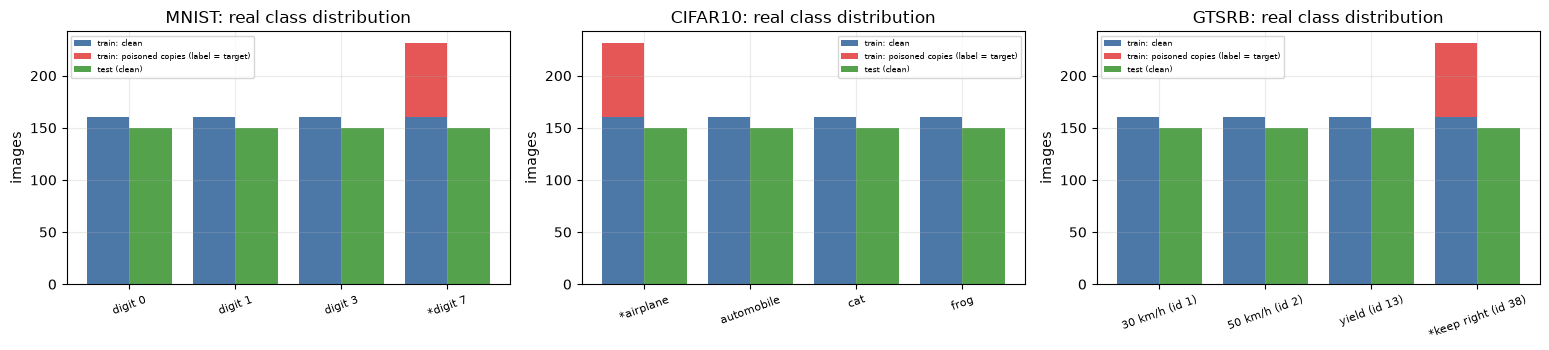

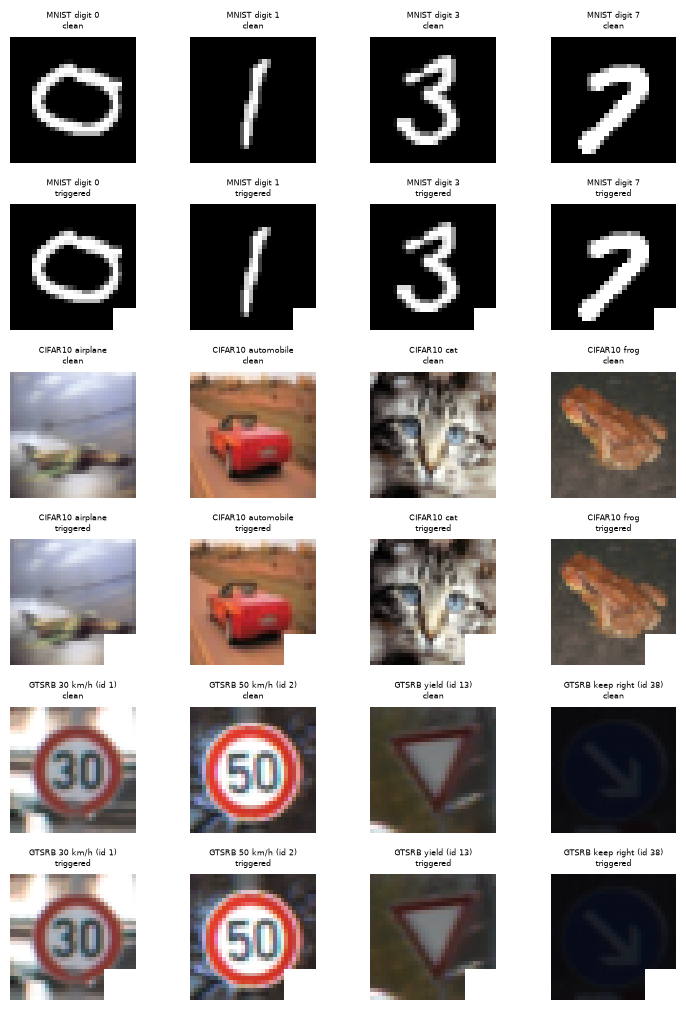

In [11]:
# (a) real class distributions: stored labels of the defender's training split (clean originals + poisoned copies carry the TARGET label) and the test split
fig, axs = plt.subplots(1, len(DATASET_NAMES), figsize=(5.2 * len(DATASET_NAMES), 3.6))
axs = np.atleast_1d(axs)
for ax, name in zip(axs, DATASET_NAMES):
    W = WORLDS[(name, SEEDS[0])]; cfg = W["cfg"]; k = W["C"]; x = np.arange(k)
    clean = np.bincount(W["ytr"][W["ptr"] == 0], minlength=k); pois = np.bincount(W["ytr"][W["ptr"] == 1], minlength=k); te = np.bincount(W["yte"], minlength=k)
    ax.bar(x - 0.2, clean, 0.4, label="train: clean", color="#4C78A8"); ax.bar(x - 0.2, pois, 0.4, bottom=clean, label="train: poisoned copies (label = target)", color="#E45756")
    ax.bar(x + 0.2, te, 0.4, label="test (clean)", color="#54A24B")
    ax.set_xticks(x); ax.set_xticklabels([("*" if c == cfg["target"] else "") + n for c, n in zip(cfg["classes"], cfg["names"])], rotation=20, fontsize=8)
    ax.set_title(f"{name}: real class distribution"); ax.set_ylabel("images"); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()

# (b) examples: clean image (true class) and the same image with the trigger, for each class
fig, axs = plt.subplots(2 * len(DATASET_NAMES), 4, figsize=(7.5, 3.4 * len(DATASET_NAMES)))
for r, name in enumerate(DATASET_NAMES):
    W = WORLDS[(name, SEEDS[0])]; cfg = W["cfg"]
    for c in range(W["C"]):
        i = np.where(W["yte"] == c)[0][0]; xi = W["Xte"][i]; xt = stamp(xi[None], cfg["patch"])[0]
        for rr, im, ttl in ((2 * r, xi, "clean"), (2 * r + 1, xt, "triggered")):
            axs[rr, c].imshow(im.squeeze(), cmap="gray" if cfg["ch"] == 1 else None, vmin=0, vmax=1); axs[rr, c].axis("off")
            axs[rr, c].set_title(f"{name} {cfg['names'][c]}\n{ttl}", fontsize=6)
plt.tight_layout(); plt.show()

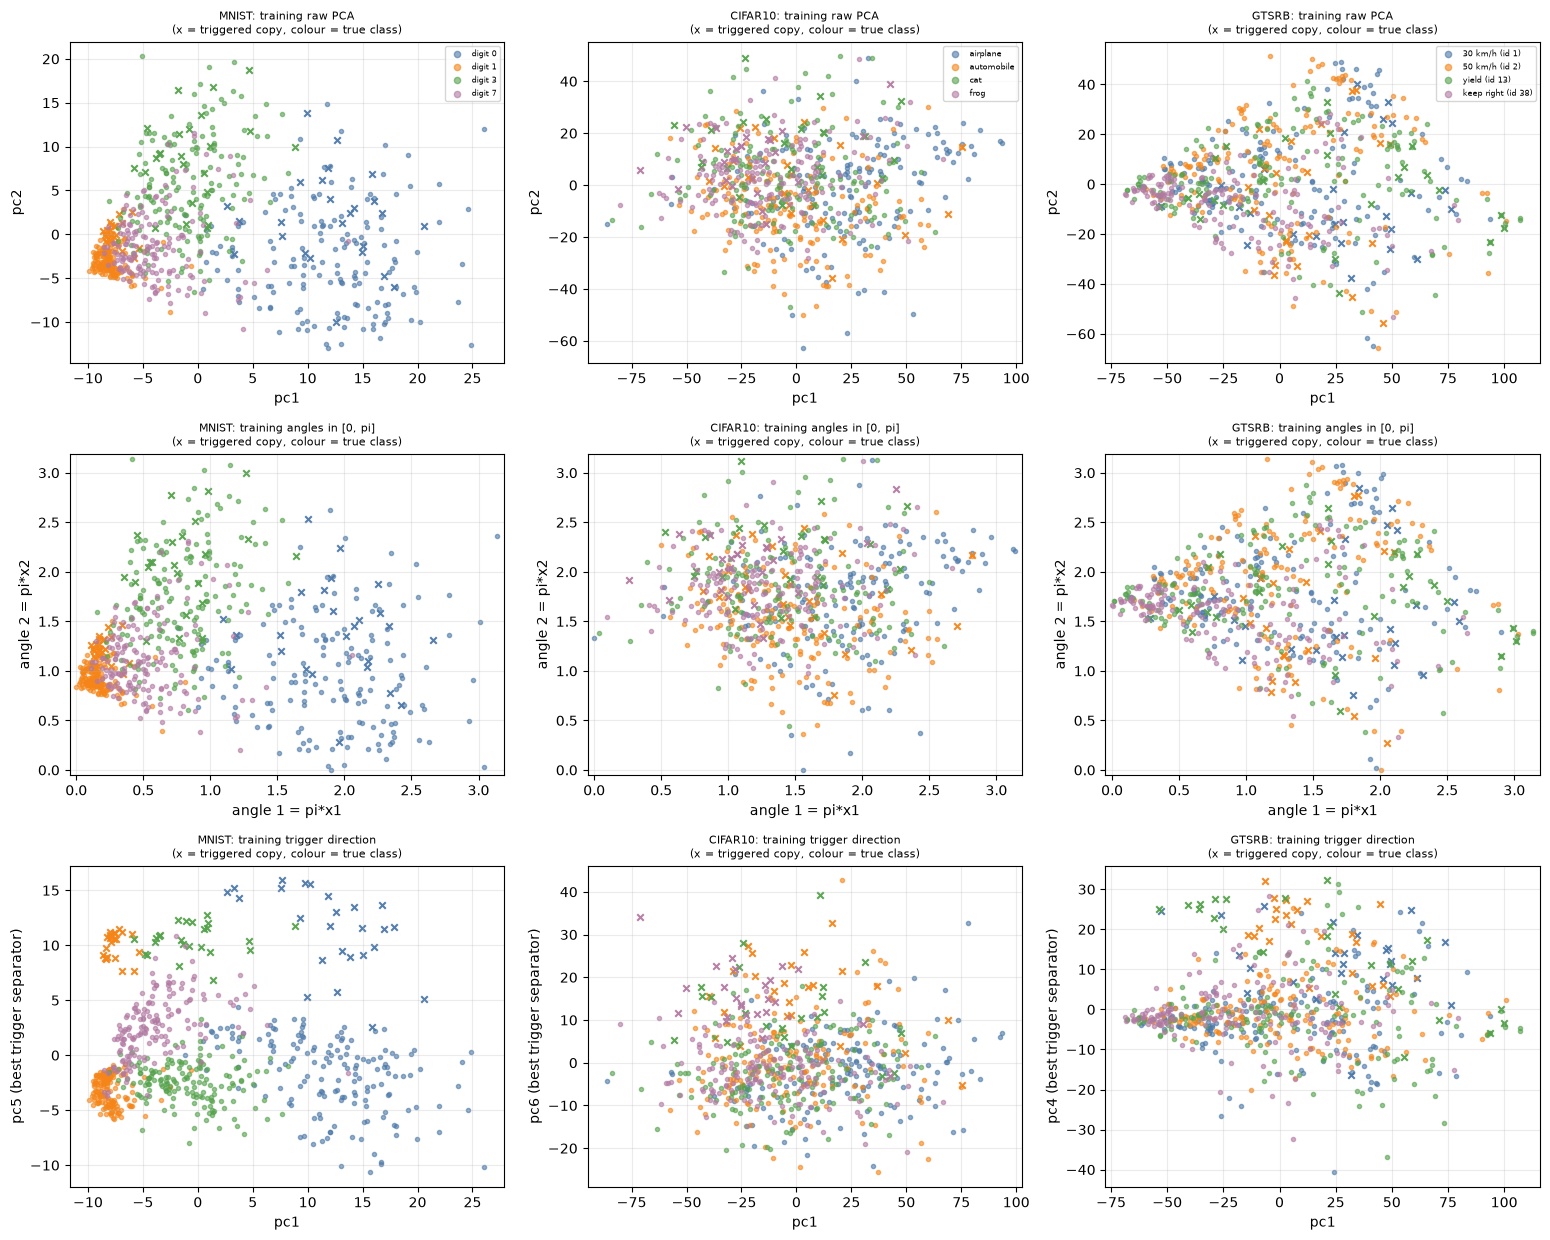

In [12]:
# (c) 2-D scatter of the real training images, coloured by GROUND-TRUTH class (poisoned copies keep the class of the image they were made from, marked x).
#     Row 1: raw PCA coordinates pc1/pc2 (PCA fitted on the training split). Row 2: the first two ANGLES the circuit receives, pi * (scaled pc), in [0, pi].
#     Row 3: pc1 against the PCA component that best separates triggered from clean images (where the backdoor is visible in feature space).
from sklearn.metrics import roc_auc_score
cols = ["#4C78A8", "#F58518", "#54A24B", "#B279A2"]
fig, axs = plt.subplots(3, len(DATASET_NAMES), figsize=(5.2 * len(DATASET_NAMES), 12.5)); axs = np.asarray(axs).reshape(3, -1)
for j, name in enumerate(DATASET_NAMES):
    W = WORLDS[(name, SEEDS[0])]; cfg = W["cfg"]; raw = W["tf"](W["Xtr"], raw=True); ang = np.pi * W["Ztr"]; isp = W["ptr"] == 1
    auc = [abs(roc_auc_score(isp, raw[:, d]) - 0.5) for d in range(N_QUBITS)]; best = int(np.argmax(auc))
    for r, (A, lab) in enumerate(((raw[:, :2], ("pc1", "pc2")), (ang[:, :2], ("angle 1 = pi*x1", "angle 2 = pi*x2")), (raw[:, [0, best]], ("pc1", f"pc{best + 1} (best trigger separator)")))):
        ax = axs[r, j]
        for c in range(W["C"]):
            m = (W["ttr"] == c) & ~isp; ax.scatter(A[m, 0], A[m, 1], s=9, color=cols[c], alpha=0.6, label=cfg["names"][c])
            m = (W["ttr"] == c) & isp;  ax.scatter(A[m, 0], A[m, 1], s=22, marker="x", color=cols[c], alpha=0.95)
        ax.set_xlabel(lab[0]); ax.set_ylabel(lab[1])
        ax.set_title(f"{name}: training {['raw PCA', 'angles in [0, pi]', 'trigger direction'][r]}\n(x = triggered copy, colour = true class)", fontsize=8)
        if r == 1: ax.set_xlim(-0.05, np.pi + 0.05); ax.set_ylim(-0.05, np.pi + 0.05)
        if r == 0: ax.legend(fontsize=6, markerscale=1.5)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The only quantum model is the QuantDoor VQC (6 qubits, 3 layers) and its randomised-encoding variant; the QRNG is a one-qubit circuit. Everything below is drawn from **PennyLane QNodes**, and the numerical checks assert that the objects that train the model (`FastSim`, the density-matrix routine) are *exactly* these circuits:

* the **executed VQC** (`make_qnode`, drawn with `qml.draw_mpl`), with the encoding angles of one real MNIST training image and the (untrained, seeded) initial weights;
* its **randomised variant**: the same circuit with the QRNG phase added to every encoding angle, drawn with the phase as an explicit second `R_y(phi)` gate per qubit. `R_y(a) R_y(b) = R_y(a + b)`, so this is the same operation as `R_y(pi x + phi)`; a cell asserts the two give identical outputs;
* the **QRNG circuit** (`H` + measurement) and the **noisy variant** with depolarising channels (`default.mixed`) used in the noise study;
* qubit count, depth and trainable-parameter count. Assumptions where the paper omits details (number of layers, order of gates inside a layer, read-out) are listed in the table in the introduction.

In [13]:
sim = FastSim(N_QUBITS, N_LAYERS)
qn = make_qnode(N_QUBITS, N_LAYERS)
M0 = QModel(N_QUBITS, N_LAYERS, 4, SEED, sim)                      # seeded initial weights (the trained weights are used later)
W0 = WORLDS[(DATASET_NAMES[0], SEEDS[0])]
theta_demo = torch.tensor(np.pi * W0["Ztr"][:6], dtype=torch.float64)               # real, scaled MNIST (or first dataset) training angles
w0 = M0.w.detach()

# --- equivalence 1: FastSim == PennyLane QNode (outputs) -------------------------------------------------------
a = sim.feats(theta_demo, w0); b = torch.stack(list(qn(theta_demo, w0)), -1)
assert torch.allclose(a, b, atol=1e-10), "FastSim differs from the QNode"
print("FastSim == PennyLane QNode on 6 real inputs: max |difference| = %.2e" % float((a - b).abs().max()))
# --- equivalence 2: autograd of FastSim == PennyLane parameter-shift rule (what the paper uses) -------------------
qps = make_qnode(N_QUBITS, N_LAYERS, diff="parameter-shift")
wa = w0.clone().requires_grad_(True); wb = w0.clone().requires_grad_(True)
torch.stack(list(qps(theta_demo[:1], wa)), -1)[0, 5].backward(); sim.feats(theta_demo[:1], wb)[0, 5].backward()
assert torch.allclose(wa.grad, wb.grad, atol=1e-10), "gradients differ"
print("d<Z_1>/d alpha: parameter-shift (PennyLane) vs back-propagation (FastSim): max |difference| = %.2e over %d parameters" % (float((wa.grad - wb.grad).abs().max()), wa.grad.numel()))
# --- equivalence 3: density-matrix routine == default.mixed with depolarising channels -------------------------------
pn = 0.02; qn_noisy = make_qnode(N_QUBITS, N_LAYERS, noise_p=pn)
c1 = sim.feats_noisy(theta_demo[:2], w0, pn); c2 = torch.stack(list(qn_noisy(theta_demo[:2], w0)), -1)
assert torch.allclose(c1, c2, atol=1e-6), "noisy simulator differs from default.mixed"
print("noisy FastSim == PennyLane default.mixed (p = %.2f): max |difference| = %.2e" % (pn, float((c1 - c2).abs().max())))

# --- the randomised variant drawn with an explicit R_y(phi) gate ------------------------------------------------
def vqc_split(x_ang, phi, weights, n=N_QUBITS, L=N_LAYERS):
    for j in range(n): qml.RY(x_ang[..., j], wires=j)           # data angle pi * x_j
    for j in range(n): qml.RY(phi, wires=j)                      # QRNG phase phi_i, the same on every qubit of sample i
    for l in range(L):
        for j in range(n):
            qml.RZ(weights[l, j, 0], wires=j); qml.RX(weights[l, j, 1], wires=j); qml.RZ(weights[l, j, 2], wires=j)
        qml.Hadamard(wires=0)
        for j in range(n - 1): qml.CNOT(wires=[j, j + 1])
    return [qml.expval(O(j)) for j in range(n) for O in OBS]
qn_split = qml.QNode(vqc_split, qml.device("default.qubit", wires=N_QUBITS), interface="torch")
bits_demo = make_qrng(SEED)(6 * KMAX); phi_demo = phases_from_bits(bits_demo, np.full(6, K0 + DK), KMAX, PHASE_SCALE)       # one flagged packet's phase (k = k0 + dk)
d1 = torch.stack(list(qn_split(theta_demo[0], float(phi_demo[0]), w0)), -1); d2 = torch.stack(list(qn(theta_demo[0] + float(phi_demo[0]), w0)), -1)
assert torch.allclose(d1, d2, atol=1e-10); print("R_y(pi x) then R_y(phi)  ==  R_y(pi x + phi): max |difference| = %.2e   (phi = %.3f rad, k = %d bits)" % (float((d1 - d2).abs().max()), phi_demo[0], K0 + DK))

FastSim == PennyLane QNode on 6 real inputs: max |difference| = 7.77e-16


d<Z_1>/d alpha: parameter-shift (PennyLane) vs back-propagation (FastSim): max |difference| = 4.44e-16 over 54 parameters


noisy FastSim == PennyLane default.mixed (p = 0.02): max |difference| = 1.28e-07


R_y(pi x) then R_y(phi)  ==  R_y(pi x + phi): max |difference| = 5.55e-16   (phi = 2.209 rad, k = 6 bits)


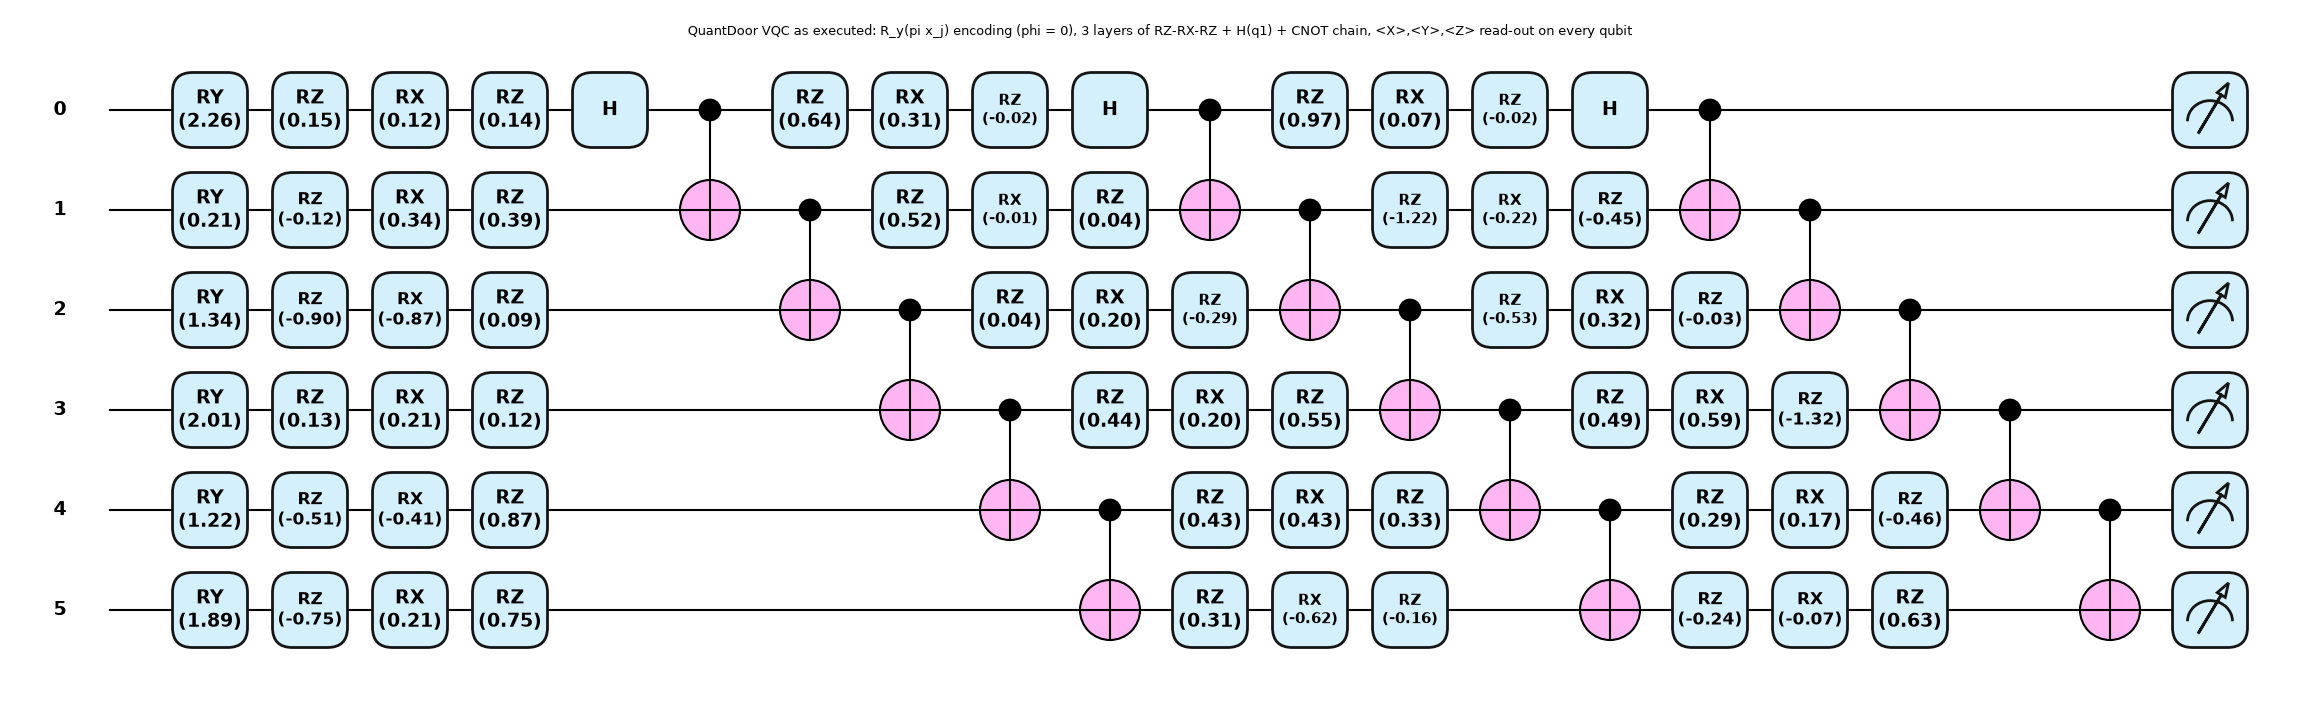

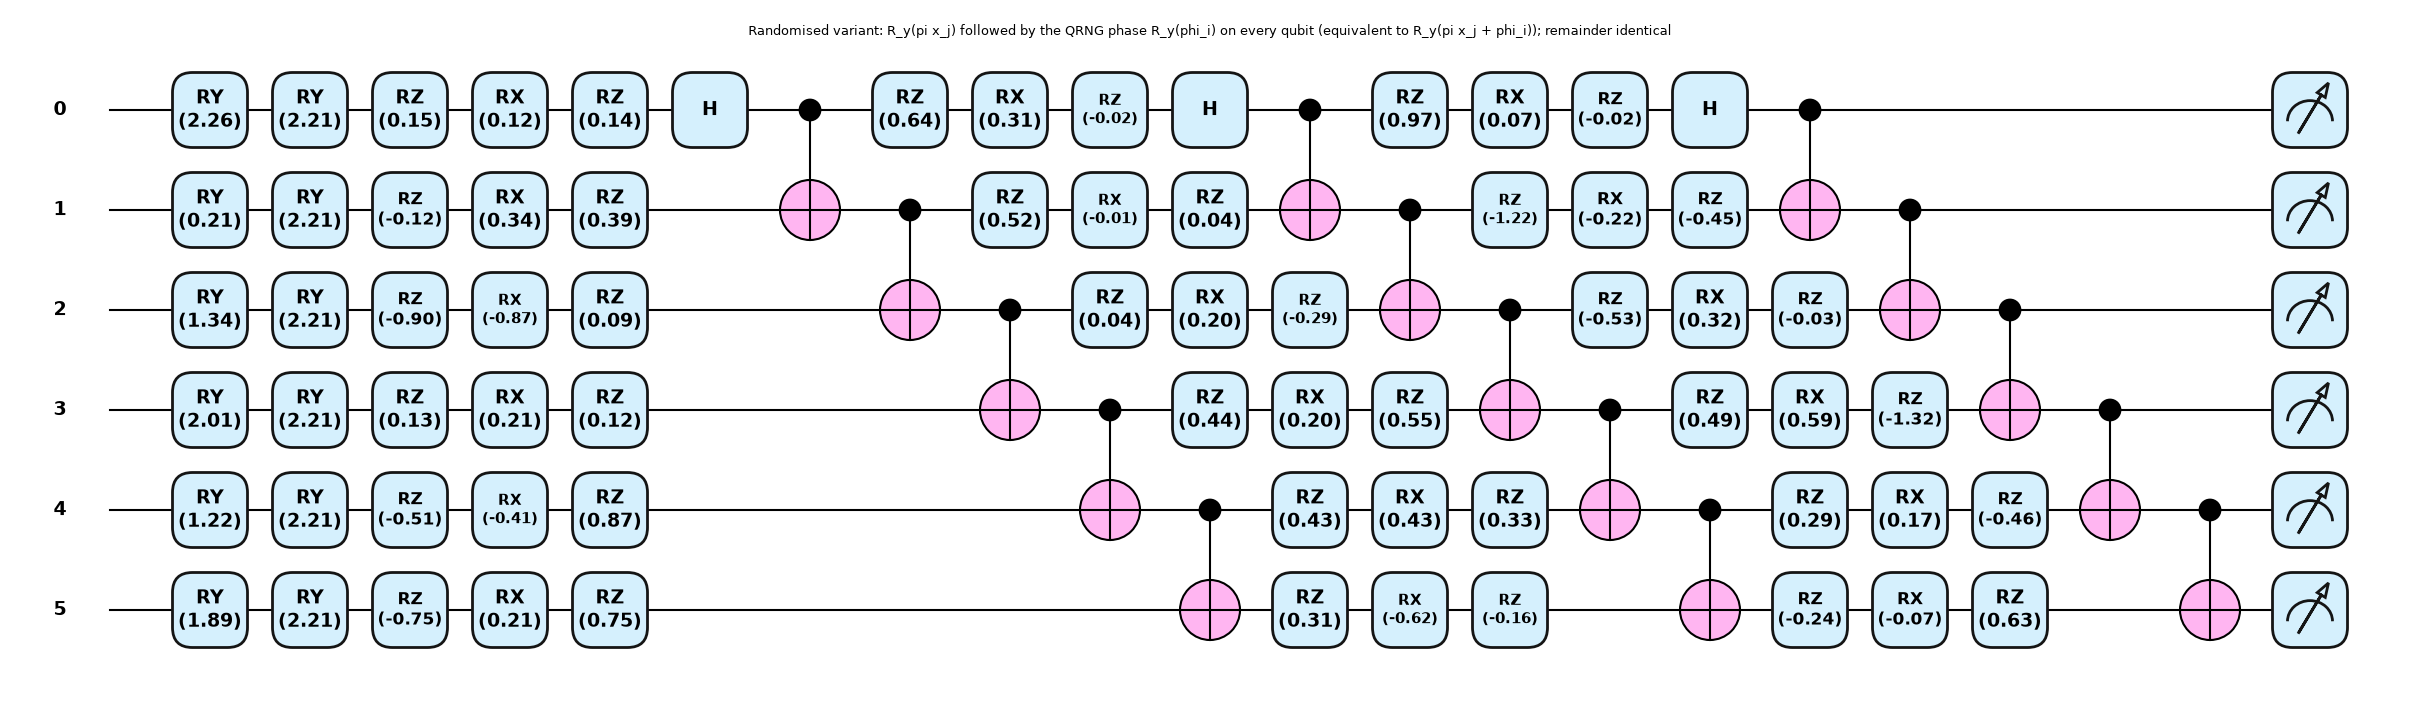

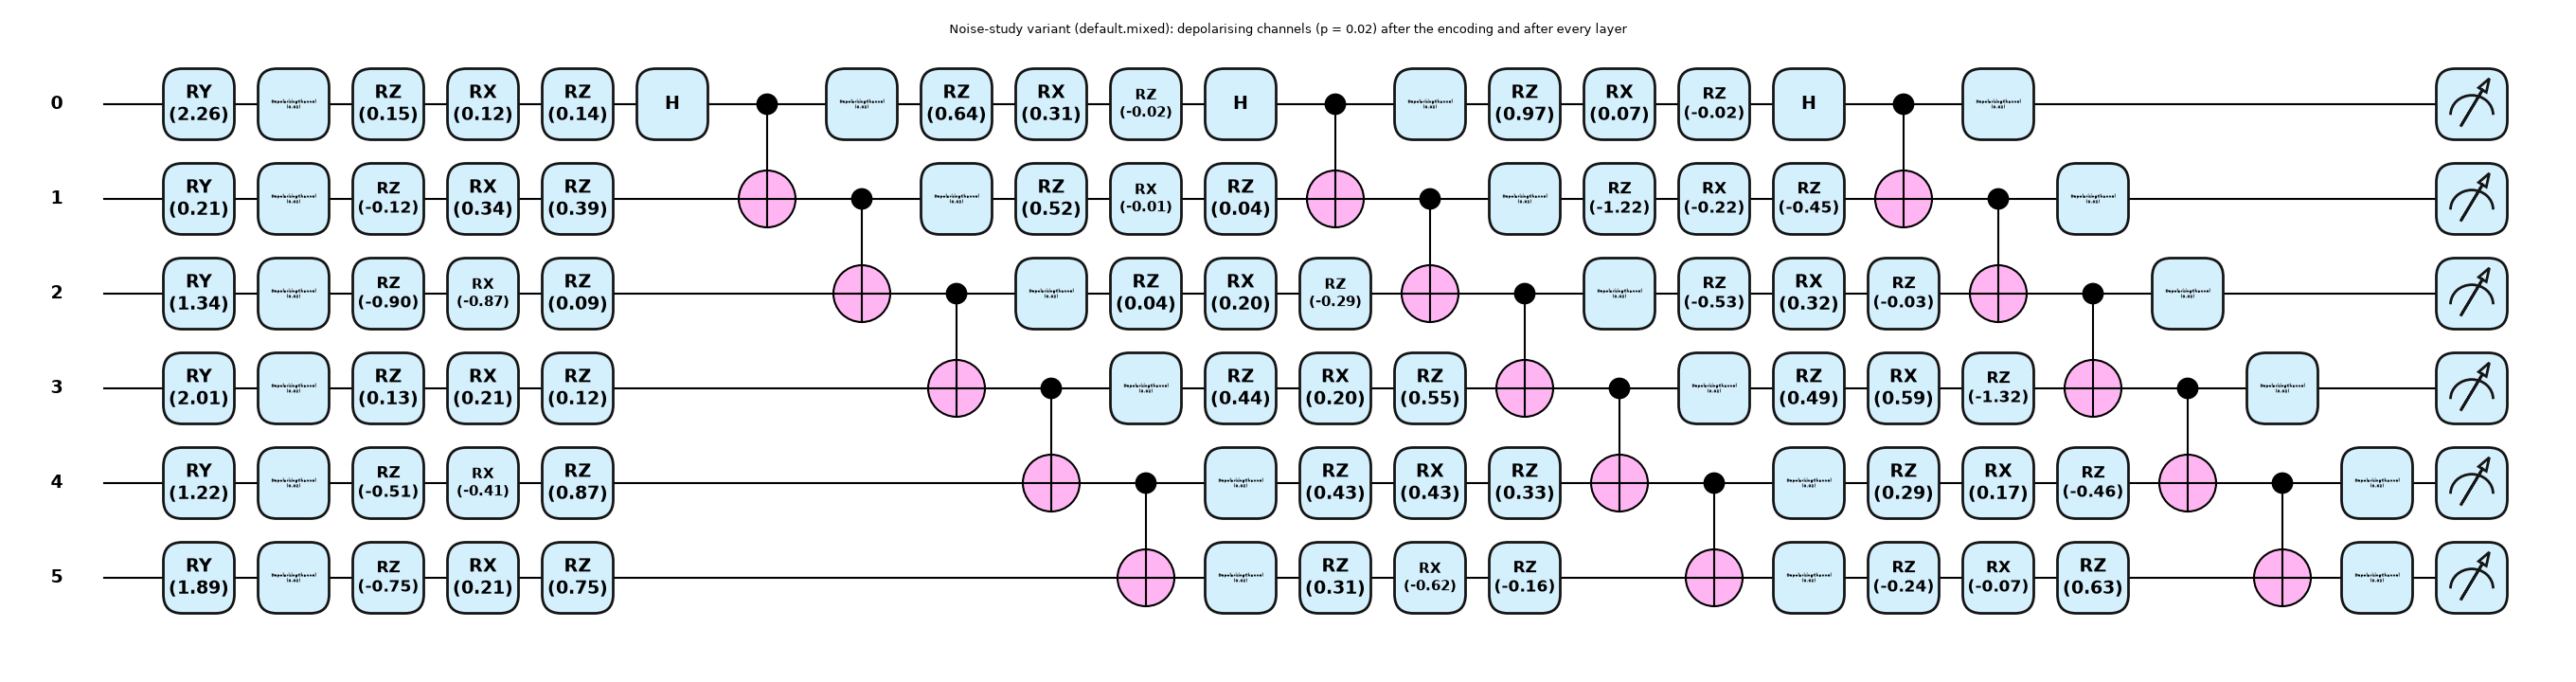

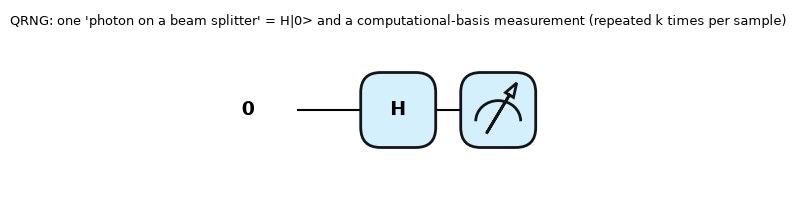

                                        qubits  depth  gates  trainable_circuit_params  classical_head_params
circuit                                                                                                      
VQC (as executed in training)                6     20     78                        54                     76
randomised variant (explicit R_y(phi))       6     21     84                        54                     76
noisy variant (depolarising)                 6     24    102                        54                     76
QRNG photon                                  1      1      1                         0                      0
trainable rotation angles = 3 layers x 6 qubits x 3 (RZ, RX, RZ) = 54;  read-out: 18 Pauli expectations -> Linear(18 -> 4) = 76 classical parameters
CNOTs per layer: 5 | Hadamards per layer: 1 | measured observables: 18


In [14]:
th1 = theta_demo[0]
fig, ax = qml.draw_mpl(qn, decimals=2, style="pennylane")(th1, w0)
fig.suptitle("QuantDoor VQC as executed: R_y(pi x_j) encoding (phi = 0), 3 layers of RZ-RX-RZ + H(q1) + CNOT chain, <X>,<Y>,<Z> read-out on every qubit", fontsize=9); plt.show()
fig, ax = qml.draw_mpl(qn_split, decimals=2, style="pennylane")(th1, float(phi_demo[0]), w0)
fig.suptitle("Randomised variant: R_y(pi x_j) followed by the QRNG phase R_y(phi_i) on every qubit (equivalent to R_y(pi x_j + phi_i)); remainder identical", fontsize=9); plt.show()
fig, ax = qml.draw_mpl(qn_noisy, decimals=2, style="pennylane")(th1, w0)
fig.suptitle("Noise-study variant (default.mixed): depolarising channels (p = 0.02) after the encoding and after every layer", fontsize=9); plt.show()
dev_q = qml.device("default.qubit", wires=1, shots=8, seed=SEED)
@qml.qnode(dev_q)
def photon():
    qml.Hadamard(wires=0); return qml.sample(wires=0)
fig, ax = qml.draw_mpl(photon, style="pennylane")(); fig.suptitle("QRNG: one 'photon on a beam splitter' = H|0> and a computational-basis measurement (repeated k times per sample)", fontsize=9); plt.show()

def specs_of(node, *args):
    sp = qml.specs(node, level="device")(*args); res = getattr(sp, "resources", sp)
    return getattr(res, "depth", None), getattr(res, "num_gates", None)
d_vqc, g_vqc = specs_of(qn, th1, w0); d_spl, g_spl = specs_of(qn_split, th1, float(phi_demo[0]), w0); d_noi, g_noi = specs_of(qn_noisy, th1, w0)
head_params = sum(p.numel() for p in M0.head.parameters())
arch = pd.DataFrame([
    dict(circuit="VQC (as executed in training)", qubits=N_QUBITS, depth=d_vqc, gates=g_vqc, trainable_circuit_params=w0.numel(), classical_head_params=head_params),
    dict(circuit="randomised variant (explicit R_y(phi))", qubits=N_QUBITS, depth=d_spl, gates=g_spl, trainable_circuit_params=w0.numel(), classical_head_params=head_params),
    dict(circuit="noisy variant (depolarising)", qubits=N_QUBITS, depth=d_noi, gates=g_noi, trainable_circuit_params=w0.numel(), classical_head_params=head_params),
    dict(circuit="QRNG photon", qubits=1, depth=1, gates=1, trainable_circuit_params=0, classical_head_params=0)]).set_index("circuit")
print(arch.to_string())
print(f"trainable rotation angles = {N_LAYERS} layers x {N_QUBITS} qubits x 3 (RZ, RX, RZ) = {w0.numel()};  read-out: {3 * N_QUBITS} Pauli expectations -> Linear({3 * N_QUBITS} -> 4) = {head_params} classical parameters")
print("CNOTs per layer:", N_QUBITS - 1, "| Hadamards per layer: 1 | measured observables:", 3 * N_QUBITS)

## 5. The experiment: attack, undefended VQC, ablations and full QuantDoor

For every dataset and seed the cell trains the six variants of section 4 on the *same* poisoned `D'`, plus (first seed) two sensitivity runs with a shrunken phase range, and two models on a **clean** `D` (no poisoning: "baseline VQC" and "VQC-QRNG" of Fig. 6b). It also runs STRIP and the classical baselines on the undefended model. The progress line shows ASR and CA of the primary (mean-phase) inference mode.

In [15]:
A_TH = aoi_threshold(np.random.default_rng(SEED))
cfg_base = dict(n_q=N_QUBITS, L=N_LAYERS, mode="det", scale=PHASE_SCALE, aoi=False, reg=False, ctrl=False, drop=False,
                k0=K0, dk=DK, kmax=KMAX, lam_rel=LAM_REL, lam_decay=LAM_DECAY, epochs=EPOCHS, bs=BATCH, lr=LR, a_th=A_TH, reenc_mean=REENC_MEAN)
VARIANTS = {
    "VQC (no defence)":      dict(mode="det"),
    "VQC + PRNG":            dict(mode="prng"),
    "VQC + QRNG":            dict(mode="qrng"),
    "AoI only (drop stale)": dict(mode="det", drop=True),
    "VQC + QRNG + AoI":      dict(mode="qrng", aoi=True),
    "QuantDoor (full)":      dict(mode="qrng", aoi=True, reg=True, ctrl=True),
}
SENS = {f"QuantDoor, phase range {s} pi": dict(mode="qrng", aoi=True, reg=True, ctrl=True, scale=s) for s in SENS_SCALES}
CLEAN = {"clean VQC": dict(mode="det"), "clean VQC + QRNG": dict(mode="qrng")}
print(f"AoI threshold A_th = {A_TH:.2f} ms | epochs {EPOCHS} | batch {BATCH} | lr {LR}")

def conv_metrics(hist, eps=0.02):
    loss = np.array([h["loss"] for h in hist]); gn = np.array([h["gnorm"] for h in hist])
    d = np.abs(np.diff(loss)); speed = int(np.argmax(d < eps)) + 1 if (d < eps).any() else len(loss)
    return dict(conv_speed=speed, conv_stability=float(loss[-5:].var()), conv_smooth=float(gn.var()))

ROWS, MODELS, STRIPS, CLASSIC = [], {}, [], []
def record(name, seed, variant, model, W):
    em, er = eval_model(model, W, "mean"), eval_model(model, W, "rand", seed)
    fl, ip = model.flag, model.isp
    ROWS.append(dict(dataset=name, seed=seed, variant=variant, CA=em["CA"], ASR=em["ASR"], CA_rand=er["CA"], ASR_rand=er["ASR"], time=model.train_time,
                     aoi_TPR=float(fl[ip == 1].mean()) if ip.sum() else np.nan, aoi_FPR=float(fl[ip == 0].mean()), k_end=model.hist[-1]["k"], **conv_metrics(model.hist)))
    return em

t_all = time.time()
for name in DATASET_NAMES:
    for seed in SEEDS:
        W = WORLDS[(name, seed)]; t0 = time.time(); runs = dict(VARIANTS)
        if seed == SEEDS[0]: runs.update(SENS)
        for v, ov in runs.items():
            m = train_model(W, {**cfg_base, **ov}, sim, seed); em = record(name, seed, v, m, W)
            if v in ("VQC (no defence)", "QuantDoor (full)") and (name == DATASET_NAMES[0]) and seed == SEEDS[0]: MODELS[(name, seed, v)] = m
            if v == "VQC (no defence)":
                STRIPS.append(dict(dataset=name, seed=seed, **strip_eval(m, W, seed)))
                CLASSIC += [dict(dataset=name, seed=seed, model=k, **r) for k, r in classical_baselines(W, seed).items()]
            print(f"  {name:8s} seed {seed} {v:34s} CA {em['CA']:.3f}  ASR {em['ASR']:.3f}  ({m.train_time:5.1f} s)", flush=True)
        Wc = make_world(name, seed, N_PC, N_TE_PC, 0.0, N_QUBITS)                           # clean data for Fig. 6b
        for v, ov in CLEAN.items():
            m = train_model(Wc, {**cfg_base, **ov}, sim, seed); em = record(name, seed, v, m, Wc)
            print(f"  {name:8s} seed {seed} {v:34s} CA {em['CA']:.3f}  ASR(natural) {em['ASR']:.3f}  ({m.train_time:5.1f} s)", flush=True)
        print(f"{name} seed {seed} done in {time.time() - t0:.0f} s")
R = pd.DataFrame(ROWS); S = pd.DataFrame(STRIPS); CL = pd.DataFrame(CLASSIC)
print(f"all runs finished in {(time.time() - t_all) / 60:.1f} min")

AoI threshold A_th = 3.76 ms | epochs 20 | batch 128 | lr 0.05


  MNIST    seed 42 VQC (no defence)                   CA 0.927  ASR 0.987  ( 11.7 s)


  MNIST    seed 42 VQC + PRNG                         CA 0.762  ASR 0.978  ( 11.1 s)


  MNIST    seed 42 VQC + QRNG                         CA 0.895  ASR 0.936  ( 12.5 s)


  MNIST    seed 42 AoI only (drop stale)              CA 0.930  ASR 0.951  (  7.3 s)


...

  GTSRB    seed 44 QuantDoor (full)                   CA 0.420  ASR 0.964  ( 43.2 s)


  GTSRB    seed 44 clean VQC                          CA 0.660  ASR(natural) 0.020  ( 13.0 s)


  GTSRB    seed 44 clean VQC + QRNG                   CA 0.643  ASR(natural) 0.000  ( 14.2 s)


GTSRB seed 44 done in 193 s


all runs finished in 23.1 min


## 6. Results: per-dataset tables and the analogue of Table 1

First the per-dataset numbers (mean +/- std over seeds; with one seed there is no std). Then the layout of the paper's **Table 1** (ASR, TPR, FNR, FPR, CA, runtime) averaged over datasets and seeds. For QuantDoor-type rows **TPR/FPR are the detection rates of the AoI alarm on the training stream** (poisoned packets flagged / clean packets flagged), which follow from the assumed delay model of section 2, not from a measurement. For STRIP they are the flag rates of the entropy test on triggered / clean test inputs. The other four defences of the paper's Table 1 cannot be run on this model; their published numbers are printed for reference only.

In [16]:
def ms(x, nd=3):
    x = np.asarray(x, float); return f"{x.mean():.{nd}f}" + (f" +/- {x.std(ddof=0):.{nd}f}" if len(x) > 1 else "")
order = list(VARIANTS) + [k for k in R.variant.unique() if k.startswith("QuantDoor, phase")] + list(CLEAN)
for col, ttl in (("ASR", "ASR (attack success rate, lower is better) - deterministic inference with the mean training phase"), ("CA", "clean accuracy")):
    P = R.pivot_table(index="variant", columns="dataset", values=col, aggfunc=lambda x: ms(x)).reindex(order)
    print(ttl); print(P[DATASET_NAMES].to_string()); print()
P = R.pivot_table(index="variant", columns="dataset", values=["ASR_rand", "CA_rand"], aggfunc=lambda x: ms(x)).reindex(order)
print("Secondary inference mode: a fresh random phase per test input (ASR_rand / CA_rand)"); print(P.to_string())

ASR (attack success rate, lower is better) - deterministic inference with the mean training phase
dataset                                   MNIST          CIFAR10            GTSRB
variant                                                                          
VQC (no defence)                0.990 +/- 0.005  0.699 +/- 0.121  0.874 +/- 0.031
VQC + PRNG                      0.982 +/- 0.008  0.596 +/- 0.104  0.859 +/- 0.075
VQC + QRNG                      0.976 +/- 0.029  0.648 +/- 0.122  0.854 +/- 0.095
AoI only (drop stale)           0.959 +/- 0.026  0.276 +/- 0.126  0.525 +/- 0.112
VQC + QRNG + AoI                0.974 +/- 0.032  0.715 +/- 0.063  0.701 +/- 0.230
QuantDoor (full)                0.967 +/- 0.016  0.647 +/- 0.207  0.902 +/- 0.048
QuantDoor, phase range 0.25 pi            0.938            0.724            0.849
QuantDoor, phase range 0.5 pi             0.942            0.809            0.922
clean VQC                       0.016 +/- 0.004  0.158 +/- 0.045  0.063 +/- 0.056


Secondary inference mode: a fresh random phase per test input (ASR_rand / CA_rand)
                                       ASR_rand                                            CA_rand                                  
dataset                                 CIFAR10            GTSRB            MNIST          CIFAR10            GTSRB            MNIST
variant                                                                                                                             
VQC (no defence)                0.699 +/- 0.121  0.874 +/- 0.031  0.990 +/- 0.005  0.509 +/- 0.025  0.587 +/- 0.007  0.932 +/- 0.004
VQC + PRNG                      0.507 +/- 0.100  0.784 +/- 0.077  0.954 +/- 0.004  0.463 +/- 0.006  0.486 +/- 0.012  0.867 +/- 0.028
VQC + QRNG                      0.535 +/- 0.058  0.760 +/- 0.095  0.919 +/- 0.018  0.451 +/- 0.018  0.504 +/- 0.009  0.892 +/- 0.019
AoI only (drop stale)           0.276 +/- 0.126  0.525 +/- 0.112  0.959 +/- 0.026  0.512 +/- 0.021  0.562 +/- 0.019  0.

In [17]:
atk = R[~R.variant.str.startswith("clean")]
rows = []
def trow(label, asr, tpr, fpr, ca, rt):
    rows.append({"Framework": label, "ASR": asr, "TPR": tpr, "FNR": (1 - tpr) if isinstance(tpr, float) else "-", "FPR": fpr, "CA": ca, "Runtime (s)": rt})
S_m = S[["TPR", "FPR", "ASR", "time"]].mean()
base = atk[atk.variant == "VQC (no defence)"]
trow("STRIP on the undefended VQC (rejects flagged inputs)", float(S_m["ASR"]), float(S_m["TPR"]), float(S_m["FPR"]), float(base.CA.mean()), float(base.time.mean() + S_m["time"]))
for nm in CL.model.unique():
    c = CL[CL.model == nm]; trow(f"{nm} on the same 6 features", float(c.ASR.mean()), "-", "-", float(c.CA.mean()), float(c.time.mean()))
for v in VARIANTS:
    a = atk[atk.variant == v]; has_aoi = v in ("AoI only (drop stale)", "VQC + QRNG + AoI", "QuantDoor (full)")
    trow(v, float(a.ASR.mean()), float(a.aoi_TPR.mean()) if has_aoi else "-", float(a.aoi_FPR.mean()) if has_aoi else "-", float(a.CA.mean()), float(a.time.mean()))
T1 = pd.DataFrame(rows).set_index("Framework")
print("Analogue of Table 1 (mean over", len(DATASET_NAMES), "dataset(s) x", len(SEEDS), "seed(s); QuantDoor-type TPR/FPR = AoI alarm on the simulated stream)")
print(T1.map(lambda x: f"{x:.3f}" if isinstance(x, float) else x).to_string())
paper_t1 = pd.DataFrame([("STRIP [5]", .41, .83, .17, .14, .96, 112.5), ("NeuralSanitizer [22]", .32, .87, .13, .09, .97, 98.3), ("A4FL [15]", .24, .91, .09, .06, .98, 84.6),
                         ("DMGNN [18]", .19, .93, .07, .05, .98, 76.4), ("CleanGen [11]", .16, .94, .06, .04, .98, 75.2), ("QuantDoor (paper)", .11, .96, .04, .03, .99, 73.8)],
                        columns=["Framework", "ASR", "TPR", "FNR", "FPR", "CA", "Runtime (s)"]).set_index("Framework")
print("\nPaper Table 1 (GPU workstation, full datasets, 10 classes unknown):"); print(paper_t1.to_string())

Analogue of Table 1 (mean over 3 dataset(s) x 3 seed(s); QuantDoor-type TPR/FPR = AoI alarm on the simulated stream)
                                                        ASR    TPR    FNR    FPR     CA Runtime (s)
Framework                                                                                          
STRIP on the undefended VQC (rejects flagged inputs)  0.834  0.021  0.979  0.047  0.676      18.056
RandomForest on the same 6 features                   0.849      -      -      -  0.702       2.619
SVC (rbf) on the same 6 features                      0.870      -      -      -  0.708       0.257
MLP (16,16) on the same 6 features                    0.837      -      -      -  0.691       8.162
VQC (no defence)                                      0.854      -      -      -  0.676      12.675
VQC + PRNG                                            0.812      -      -      -  0.605      12.558
VQC + QRNG                                            0.826      -      -      -  0

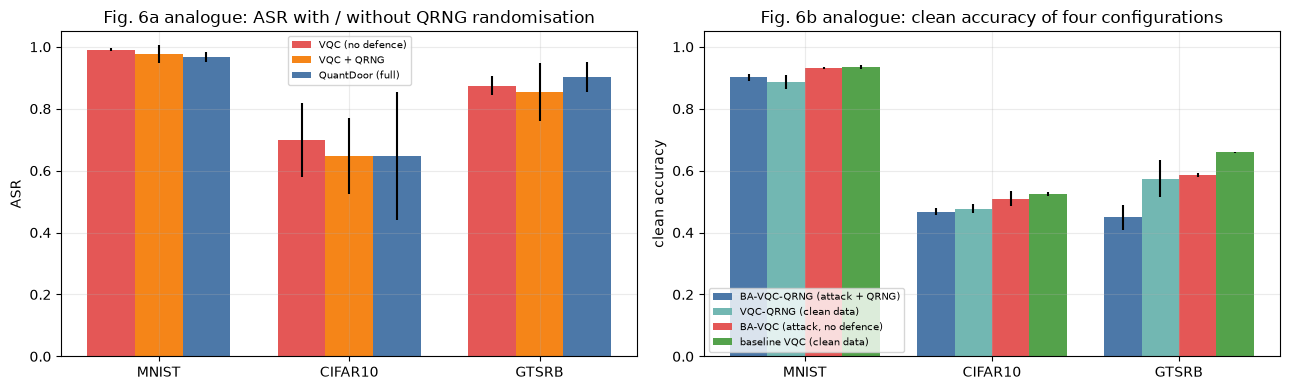

In [18]:
# Fig. 6a/6b analogues: ASR with and without the quantum randomisation, and clean accuracy of the four configurations
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(DATASET_NAMES)); w = 0.2
for i, (v, c) in enumerate((("VQC (no defence)", "#E45756"), ("VQC + QRNG", "#F58518"), ("QuantDoor (full)", "#4C78A8"))):
    m = [R[(R.variant == v) & (R.dataset == d)].ASR.mean() for d in DATASET_NAMES]; e = [R[(R.variant == v) & (R.dataset == d)].ASR.std(ddof=0) for d in DATASET_NAMES]
    axs[0].bar(x + (i - 1) * 0.25, m, 0.25, yerr=e, color=c, label=v)
axs[0].set_xticks(x); axs[0].set_xticklabels(DATASET_NAMES); axs[0].set_ylabel("ASR"); axs[0].set_title("Fig. 6a analogue: ASR with / without QRNG randomisation"); axs[0].legend(fontsize=7); axs[0].set_ylim(0, 1.05)
cfgs = [("BA-VQC-QRNG (attack + QRNG)", "VQC + QRNG", "#4C78A8"), ("VQC-QRNG (clean data)", "clean VQC + QRNG", "#72B7B2"), ("BA-VQC (attack, no defence)", "VQC (no defence)", "#E45756"), ("baseline VQC (clean data)", "clean VQC", "#54A24B")]
for i, (lab, v, c) in enumerate(cfgs):
    m = [R[(R.variant == v) & (R.dataset == d)].CA.mean() for d in DATASET_NAMES]; e = [R[(R.variant == v) & (R.dataset == d)].CA.std(ddof=0) for d in DATASET_NAMES]
    axs[1].bar(x + (i - 1.5) * 0.2, m, 0.2, yerr=e, color=c, label=lab)
axs[1].set_xticks(x); axs[1].set_xticklabels(DATASET_NAMES); axs[1].set_ylabel("clean accuracy"); axs[1].set_title("Fig. 6b analogue: clean accuracy of four configurations"); axs[1].legend(fontsize=7, loc="lower left"); axs[1].set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

## 7. Network analysis (Fig. 4): AoI of benign and poisoned packets

Left: the simulated AoI trace of a packet stream with 10 % poisoned packets. By construction (extra re-encoding delay) the poisoned packets produce spikes; this reproduces the *shape* of Fig. 4a but cannot validate it, because the assumption that poison arrives late is built in. Right (Fig. 4b analogue): ASR of the QuantDoor-type defences when the extra re-encoding delay grows (0 = poisoned packets look like benign ones, so the AoI alarm is blind). The undefended VQC and the QRNG without AoI do not depend on the delay.

flag rate at A_th: poisoned 0.67, benign 0.06


 reenc   ASR    CA   tpr   fpr
   0.0 0.940 0.772 0.028 0.034
   2.0 0.947 0.787 0.352 0.034
   4.0 0.944 0.785 0.507 0.034
   8.0 0.951 0.798 0.676 0.034


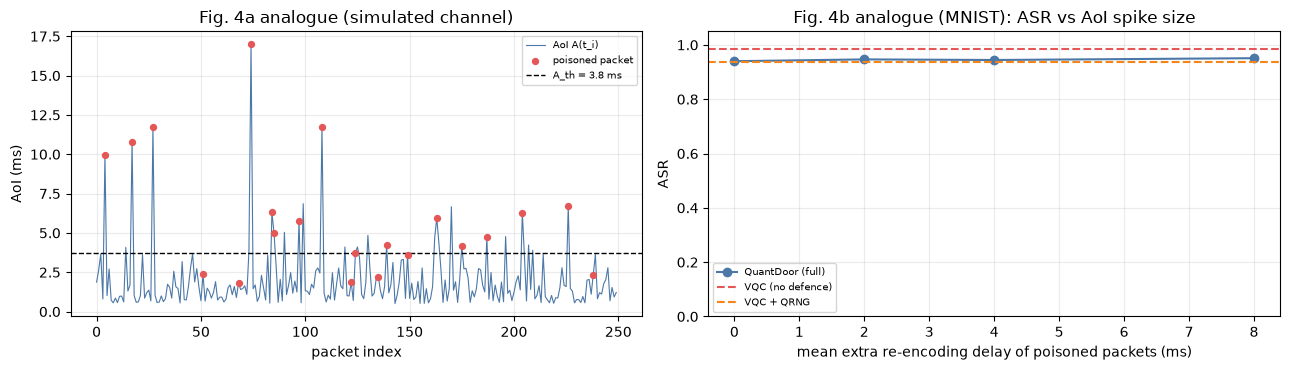

In [19]:
rng = np.random.default_rng(SEED); is_p = (rng.random(250) < POISON_FRAC).astype(float); A = simulate_aoi(is_p, rng)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
axs[0].plot(A, color="#4C78A8", lw=0.8, label="AoI A(t_i)"); axs[0].scatter(np.where(is_p == 1)[0], A[is_p == 1], color="#E45756", s=18, zorder=3, label="poisoned packet")
axs[0].axhline(A_TH, color="k", ls="--", lw=1, label=f"A_th = {A_TH:.1f} ms"); axs[0].set_xlabel("packet index"); axs[0].set_ylabel("AoI (ms)"); axs[0].set_title("Fig. 4a analogue (simulated channel)"); axs[0].legend(fontsize=7)
print(f"flag rate at A_th: poisoned {np.mean(A[is_p == 1] > A_TH):.2f}, benign {np.mean(A[is_p == 0] > A_TH):.2f}")
name0, seed0 = DATASET_NAMES[0], SEEDS[0]; W = WORLDS[(name0, seed0)]; sw = []
for r in REENC_SWEEP:
    m = train_model(W, {**cfg_base, "mode": "qrng", "aoi": True, "reg": True, "ctrl": True, "reenc_mean": r}, sim, seed0)
    sw.append(dict(reenc=r, ASR=eval_model(m, W, "mean")["ASR"], CA=eval_model(m, W, "mean")["CA"], tpr=float(m.flag[m.isp == 1].mean()), fpr=float(m.flag[m.isp == 0].mean())))
SW = pd.DataFrame(sw); print(SW.round(3).to_string(index=False))
axs[1].plot(SW.reenc, SW.ASR, "o-", color="#4C78A8", label="QuantDoor (full)")
for v, c in (("VQC (no defence)", "#E45756"), ("VQC + QRNG", "#F58518")):
    axs[1].axhline(R[(R.variant == v) & (R.dataset == name0) & (R.seed == seed0)].ASR.iloc[0], color=c, ls="--", label=v)
axs[1].set_xlabel("mean extra re-encoding delay of poisoned packets (ms)"); axs[1].set_ylabel("ASR"); axs[1].set_title(f"Fig. 4b analogue ({name0}): ASR vs AoI spike size"); axs[1].legend(fontsize=7); axs[1].set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

## 8. Randomness analysis (Fig. 5)

Following the paper: sequences of 36 bits; (a) the **Hamming distance** between independent sequences (ideal mean 18, binomial with std 3); (b) the **zero-lag correlation coefficient** between paired sequences (ideal: centred on 0). Three sources are compared: the simulated QRNG (`H|0>` samples), NumPy's Mersenne-twister PRNG and the operating-system entropy pool (the stand-in for the paper's "hardware RNG"). All three are expected to pass such simple tests; a *simulated* QRNG cannot be better than a good PRNG, and a physical one would have to be measured on a device.

In [20]:
from math import erfc, sqrt

def rng_sequences(kind, n_seq, nbits, seed):
    if kind == "QRNG (simulated photon)": b = make_qrng(seed)(n_seq * nbits)
    elif kind == "PRNG (Mersenne twister)": b = np.random.RandomState(seed).randint(0, 2, n_seq * nbits)
    else: b = np.unpackbits(np.frombuffer(os.urandom(n_seq * nbits), dtype=np.uint8))[: n_seq * nbits]   # OS entropy pool
    return np.asarray(b).reshape(n_seq, nbits).astype(int)

def randomness_stats(seqs):
    a, b = seqs[0::2], seqs[1::2][: len(seqs[0::2])]
    ham = (a != b).sum(1)                                                              # inter-sequence Hamming distance, ideal mean nbits/2
    ac, bc = a - a.mean(1, keepdims=True), b - b.mean(1, keepdims=True)
    cc = (ac * bc).sum(1) / (np.sqrt((ac ** 2).sum(1) * (bc ** 2).sum(1)) + 1e-12)     # zero-lag correlation coefficient of paired sequences
    s = seqs.sum(); n = seqs.size; p_mono = erfc(abs(2 * s - n) / sqrt(2 * n))         # NIST SP 800-22 frequency (monobit) test
    return ham, cc, p_mono

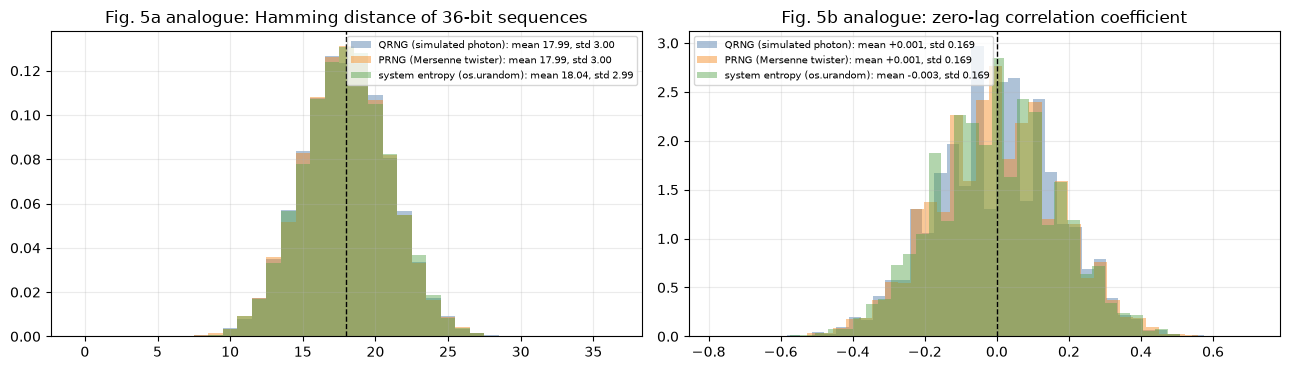

                             hamming_mean  hamming_std  corr_mean  corr_std  monobit_p
QRNG (simulated photon)           17.9940       3.0049     0.0007    0.1694     0.7251
PRNG (Mersenne twister)           17.9876       3.0029     0.0008    0.1693     0.4266
system entropy (os.urandom)       18.0433       2.9949    -0.0027    0.1688     0.7515
ideal: Hamming mean 18, std 3; correlation mean 0, std about 1/sqrt(35) = 0.169; monobit p > 0.01 passes


In [21]:
kinds = ["QRNG (simulated photon)", "PRNG (Mersenne twister)", "system entropy (os.urandom)"]
stats = {}
for kd in kinds:
    sq = rng_sequences(kd if kd.startswith(("QRNG", "PRNG")) else "os", 2 * N_RNG_SEQ, RNG_BITS, SEED); stats[kd] = randomness_stats(sq)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8)); cs = ["#4C78A8", "#F58518", "#54A24B"]
for kd, c in zip(kinds, cs):
    ham, cc, pm = stats[kd]
    axs[0].hist(ham, bins=np.arange(-0.5, RNG_BITS + 1.5), density=True, alpha=0.45, color=c, label=f"{kd}: mean {ham.mean():.2f}, std {ham.std():.2f}")
    axs[1].hist(cc, bins=40, density=True, alpha=0.45, color=c, label=f"{kd}: mean {cc.mean():+.3f}, std {cc.std():.3f}")
axs[0].axvline(RNG_BITS / 2, color="k", ls="--", lw=1); axs[0].set_title("Fig. 5a analogue: Hamming distance of 36-bit sequences"); axs[0].legend(fontsize=7)
axs[1].axvline(0, color="k", ls="--", lw=1); axs[1].set_title("Fig. 5b analogue: zero-lag correlation coefficient"); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(pd.DataFrame({kd: dict(hamming_mean=stats[kd][0].mean(), hamming_std=stats[kd][0].std(), corr_mean=stats[kd][1].mean(), corr_std=stats[kd][1].std(), monobit_p=stats[kd][2]) for kd in kinds}).T.round(4).to_string())
print("ideal: Hamming mean 18, std 3; correlation mean 0, std about 1/sqrt(35) = 0.169; monobit p > 0.01 passes")

## 9. Convergence (Fig. 7)

(a) Evolution of the regulariser weight `lambda`, the gradient variance `V_grad` and the mean QRNG precision `k` during training of the full model. (b) The paper's three convergence properties for the variants: *speed* = first epoch after which the epoch-to-epoch loss change stays below `eps = 0.02` (fewer is faster), *stability* = variance of the loss over the last 5 epochs, *smoothness* = variance of the gradient norm across epochs. The paper compares against CleanGen, A4FL and DMGNN, which cannot be run here; the comparison below is among the VQC variants.

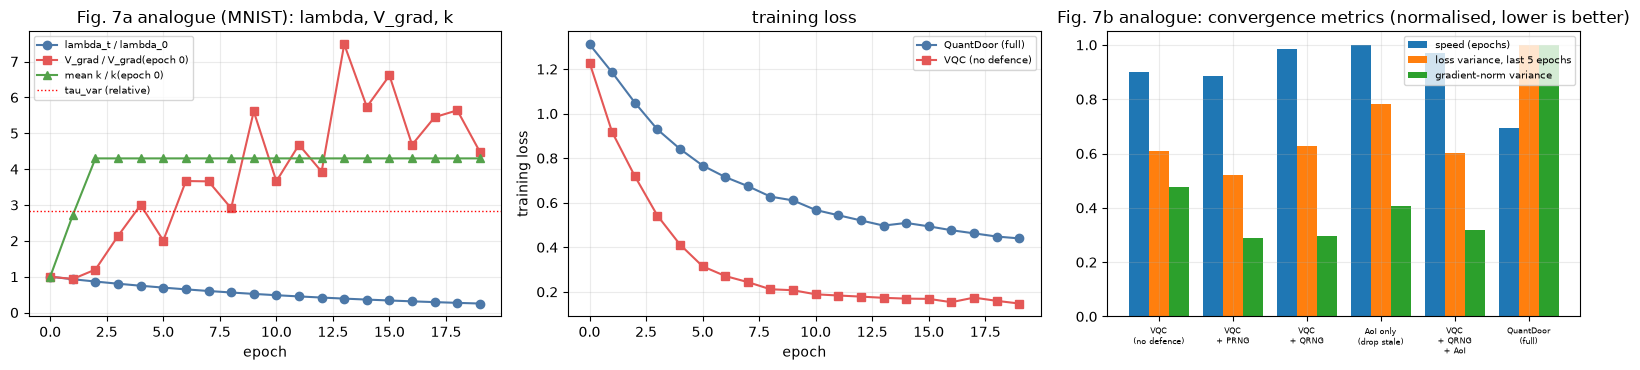

                       conv_speed  conv_stability  conv_smooth
variant                                                       
VQC (no defence)          6.88889         0.00019      0.01537
VQC + PRNG                6.77778         0.00016      0.00941
VQC + QRNG                7.55556         0.00020      0.00964
AoI only (drop stale)     7.66667         0.00024      0.01313
VQC + QRNG + AoI          7.44444         0.00019      0.01033
QuantDoor (full)          5.33333         0.00031      0.03237


In [22]:
mf = MODELS[(DATASET_NAMES[0], SEEDS[0], "QuantDoor (full)")]; H = pd.DataFrame(mf.hist)
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
axs[0].plot(H.epoch, H.lam / H.lam.iloc[0], "o-", color="#4C78A8", label="lambda_t / lambda_0"); axs[0].plot(H.epoch, H.vgrad / H.vgrad.iloc[0], "s-", color="#E45756", label="V_grad / V_grad(epoch 0)")
axs[0].plot(H.epoch, H.k / H.k.iloc[0], "^-", color="#54A24B", label="mean k / k(epoch 0)"); axs[0].axhline(mf.tau / H.vgrad.iloc[0], color="r", ls=":", lw=1, label="tau_var (relative)")
axs[0].set_xlabel("epoch"); axs[0].set_title(f"Fig. 7a analogue ({DATASET_NAMES[0]}): lambda, V_grad, k"); axs[0].legend(fontsize=7)
axs[1].plot(H.epoch, H.loss, "o-", color="#4C78A8", label="QuantDoor (full)"); h0 = pd.DataFrame(MODELS[(DATASET_NAMES[0], SEEDS[0], "VQC (no defence)")].hist)
axs[1].plot(h0.epoch, h0.loss, "s-", color="#E45756", label="VQC (no defence)"); axs[1].set_xlabel("epoch"); axs[1].set_ylabel("training loss"); axs[1].set_title("training loss"); axs[1].legend(fontsize=7)
CM = atk[atk.variant.isin(VARIANTS)].groupby("variant")[["conv_speed", "conv_stability", "conv_smooth"]].mean().reindex(list(VARIANTS))
Xn = CM / CM.max(); xx = np.arange(len(CM))
for i, (c, lab) in enumerate((("conv_speed", "speed (epochs)"), ("conv_stability", "loss variance, last 5 epochs"), ("conv_smooth", "gradient-norm variance"))): axs[2].bar(xx + (i - 1) * 0.27, Xn[c], 0.27, label=lab)
axs[2].set_xticks(xx); axs[2].set_xticklabels([v.replace(" (", "\n(").replace(" + ", "\n+ ") for v in CM.index], fontsize=6); axs[2].set_title("Fig. 7b analogue: convergence metrics (normalised, lower is better)"); axs[2].legend(fontsize=7)
plt.tight_layout(); plt.show(); print(CM.round(5).to_string())

## 10. Noise feasibility and component contributions (Fig. 8)

**(a)** The trained undefended VQC and the trained QuantDoor model of the first dataset are evaluated under a **depolarising channel** of strength `p` on every qubit after the encoding and after each layer (exact density-matrix simulation of the same circuit, asserted equal to PennyLane's `default.mixed` above). The paper says the ASR decreases monotonically with noise; the cell also prints the clean accuracy, because a model that is destroyed by noise trivially stops being a backdoored classifier. Bands are 95 % bootstrap intervals over the test inputs.
**(b)** Mean ASR of each ablation (PRNG, QRNG, AoI-only, QRNG+AoI, full) over datasets and seeds.

           model     p   ASR    lo    hi    CA
VQC (no defence) 0.000 0.985 0.965 1.000 0.935
VQC (no defence) 0.005 0.985 0.965 1.000 0.935
VQC (no defence) 0.010 0.985 0.965 1.000 0.935
VQC (no defence) 0.020 0.985 0.965 1.000 0.940
VQC (no defence) 0.050 0.985 0.965 1.000 0.955
VQC (no defence) 0.100 1.000 1.000 1.000 0.575
QuantDoor (full) 0.000 0.945 0.910 0.970 0.820
QuantDoor (full) 0.005 0.950 0.915 0.975 0.820
QuantDoor (full) 0.010 0.955 0.925 0.980 0.820
QuantDoor (full) 0.020 0.960 0.930 0.985 0.810
QuantDoor (full) 0.050 0.975 0.950 0.995 0.715
QuantDoor (full) 0.100 0.995 0.985 1.000 0.650


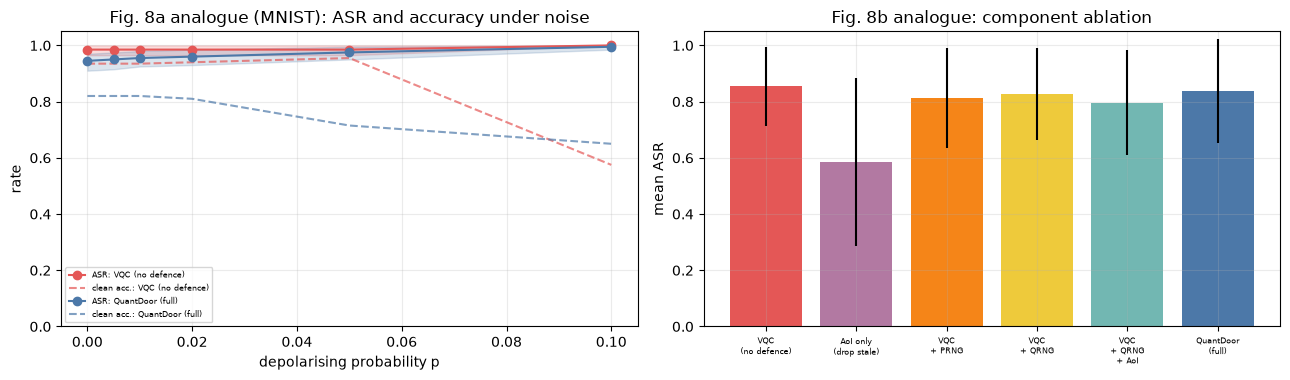

In [23]:
name0, seed0 = DATASET_NAMES[0], SEEDS[0]; W = WORLDS[(name0, seed0)]; rng = np.random.default_rng(SEED); NZ = []
for v in ("VQC (no defence)", "QuantDoor (full)"):
    m = MODELS[(name0, seed0, v)]
    for p in NOISE_PS:
        e = eval_model(m, W, "mean", p=p if p > 0 else None, n_max=N_NOISE); hit = (e["pt"].argmax(1) == W["target"]).astype(float)
        bs = [rng.choice(hit, len(hit)).mean() for _ in range(500)]
        NZ.append(dict(model=v, p=p, ASR=hit.mean(), lo=np.quantile(bs, .025), hi=np.quantile(bs, .975), CA=e["CA"]))
NZ = pd.DataFrame(NZ); print(NZ.round(3).to_string(index=False))
fig, axs = plt.subplots(1, 2, figsize=(13, 3.9))
for v, c in (("VQC (no defence)", "#E45756"), ("QuantDoor (full)", "#4C78A8")):
    d = NZ[NZ.model == v]; axs[0].plot(d.p, d.ASR, "o-", color=c, label=f"ASR: {v}"); axs[0].fill_between(d.p, d.lo, d.hi, color=c, alpha=0.2); axs[0].plot(d.p, d.CA, "--", color=c, alpha=0.7, label=f"clean acc.: {v}")
axs[0].set_xlabel("depolarising probability p"); axs[0].set_ylabel("rate"); axs[0].set_title(f"Fig. 8a analogue ({name0}): ASR and accuracy under noise"); axs[0].legend(fontsize=6); axs[0].set_ylim(0, 1.05)
comp = ["VQC (no defence)", "AoI only (drop stale)", "VQC + PRNG", "VQC + QRNG", "VQC + QRNG + AoI", "QuantDoor (full)"]
cm = [atk[atk.variant == v].ASR.mean() for v in comp]; ce = [atk[atk.variant == v].ASR.std(ddof=0) for v in comp]
axs[1].bar(range(len(comp)), cm, yerr=ce, color=["#E45756", "#B279A2", "#F58518", "#EECA3B", "#72B7B2", "#4C78A8"])
axs[1].set_xticks(range(len(comp))); axs[1].set_xticklabels([c.replace(" (", "\n(").replace(" + ", "\n+ ") for c in comp], fontsize=6); axs[1].set_ylabel("mean ASR"); axs[1].set_title("Fig. 8b analogue: component ablation"); axs[1].set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

## 11. Checking Theorem 3.1 numerically

The theorem claims that for phases `phi ~ U[0, pi]` the **expected gradient** `E_phi[grad_alpha L_sup]` of a poisoned sample is **zero** (the argument: "orthogonality of the harmonics `sin(k phi)`, `cos(k phi)` on `[0, pi]`") while the variance is positive. On `[0, pi]` the functions `cos(k phi)` average to zero for every integer `k >= 1`, but `sin(k phi)` averages to `(1 - cos(k pi))/(k pi)`, i.e. `2/(k pi)` for odd `k` (the circuit's expectation values are trigonometric in `phi` with a half-angle dependence through `R_y`). So the claim is not obviously true, and it is cheap to test: for poisoned training images and the trained QuantDoor weights, draw many phases, compute the per-phase gradient, and compare the norm of the *mean* gradient with the mean norm of the individual gradients (a ratio near 0 would support the theorem, near 1 would mean the phase noise does not average out).

In [24]:
m = MODELS[(DATASET_NAMES[0], SEEDS[0], "QuantDoor (full)")]; W = WORLDS[(DATASET_NAMES[0], SEEDS[0])]
rng = np.random.default_rng(SEED); n_draw = 30 if FAST_MODE else 60; out = []
for i in np.where(W["ptr"] == 1)[0][:3]:
    z = torch.tensor(W["Ztr"][i:i + 1], dtype=torch.float64); y = torch.tensor(W["ytr"][i:i + 1]); gs = []
    phis = phases_from_bits(rng.integers(0, 2, n_draw * KMAX), np.full(n_draw, KMAX), KMAX, PHASE_SCALE)
    for ph in phis:
        m.zero_grad(); F.cross_entropy(m(np.pi * z + float(ph)), y).backward(); gs.append(m.w.grad.flatten().clone())
    G = torch.stack(gs); out.append(dict(poisoned_sample=int(i), norm_of_mean_grad=float(G.mean(0).norm()), mean_norm_of_grad=float(G.norm(dim=1).mean()),
                                         ratio=float(G.mean(0).norm() / G.norm(dim=1).mean()), grad_std_over_phi=float(G.std(0).mean())))
TH = pd.DataFrame(out); print(TH.round(4).to_string(index=False)); THEOREM_RATIO = float(TH.ratio.mean())
print(f"mean ratio ||E_phi grad|| / E_phi||grad|| = {THEOREM_RATIO:.3f}  (theorem: 0; a ratio of 1 means no cancellation at all)")

 poisoned_sample  norm_of_mean_grad  mean_norm_of_grad  ratio  grad_std_over_phi
             640             0.0529             0.0787 0.6723             0.0155
             641             0.2741             0.3503 0.7826             0.0511
             642             0.1286             0.1689 0.7611             0.0224
mean ratio ||E_phi grad|| / E_phi||grad|| = 0.739  (theorem: 0; a ratio of 1 means no cancellation at all)


## 12. Side-by-side with the paper

Verdict rule: "reproduced" when the notebook value is within 0.02 (accuracies, rates) of the paper's, or the stated inequality / ordering holds; otherwise "not reached" or "exceeded" with the gap; "cannot be checked" when the quantity has no counterpart here (other defences, GPU runtimes, physical QRNG, a simulated channel). The notebook is a small-scale CPU replication (4 classes, 6 qubits, a few hundred images, PCA features), so absolute numbers say little; the **orderings and inequalities** are the meaningful checks.

In [25]:
claims = []
def claim(name, paper, ours, verdict, note=""): claims.append({"claim": name, "paper": paper, "notebook": ours, "verdict": verdict, "note": note})
def near(p, o, tol=0.02, better="lower"):
    if abs(o - p) <= tol: return "reproduced"
    return (("exceeded" if o < p else "not reached") if better == "lower" else ("exceeded" if o > p else "not reached")) + f" (gap {o - p:+.3f})"
g = lambda v, c: float(R[R.variant == v][c].mean())
qd_asr, qd_ca, qd_t = g("QuantDoor (full)", "ASR"), g("QuantDoor (full)", "CA"), g("QuantDoor (full)", "time")
no_asr, no_ca, no_t = g("VQC (no defence)", "ASR"), g("VQC (no defence)", "CA"), g("VQC (no defence)", "time")
strip_asr, strip_tpr, strip_fpr = float(S.ASR.mean()), float(S.TPR.mean()), float(S.FPR.mean())
claim("Table 1: QuantDoor ASR", "0.11", f"{qd_asr:.3f}", near(0.11, qd_asr), "averaged over datasets (4-class, 6-qubit, PCA-feature task)")
claim("Table 1: QuantDoor clean accuracy", "0.99", f"{qd_ca:.3f}", near(0.99, qd_ca, better="higher"), "4-class VQC on 6 PCA features cannot reach 0.99 on CIFAR-10 / GTSRB even without defence")
claim("Table 1: QuantDoor TPR / FPR", "0.96 / 0.03", f"{g('QuantDoor (full)', 'aoi_TPR'):.2f} / {g('QuantDoor (full)', 'aoi_FPR'):.2f}", "cannot be checked", "AoI alarm rates follow from the assumed delay model (section 2); not a measurement")
claim("Table 1: lowest runtime (73.8 s vs 75-112 s)", "QuantDoor fastest", f"QuantDoor {qd_t:.0f} s vs undefended {no_t:.0f} s", "reproduced" if qd_t <= no_t else "not reached", "paper compares to other defences on GPU; here the cheaper comparison is the undefended VQC")
rel = 1 - qd_asr / no_asr if no_asr > 0 else float("nan")
claim("ASR reduced by 45-60 % (abstract) - versus the undefended VQC", "45-60 %", f"{100 * rel:.0f} %", "reproduced" if rel >= 0.45 else "not reached", "paper's reference defences (CleanGen, A4FL, DMGNN) cannot be run on this model")
rel_s = 1 - qd_asr / strip_asr if strip_asr > 0 else float("nan")
claim("ASR reduced by 45-60 % - versus STRIP on the same VQC", "45-60 %", f"{100 * rel_s:.0f} %", "reproduced" if rel_s >= 0.45 else "not reached", f"STRIP: ASR after rejection {strip_asr:.3f}, TPR {strip_tpr:.2f}, FPR {strip_fpr:.2f}")
claim("Clean accuracy improves by up to 2.5 % (abstract)", "+2.5 points vs baselines", f"{100 * (qd_ca - no_ca):+.1f} points vs undefended VQC", "reproduced" if qd_ca - no_ca >= 0.025 else "not reached", "the undefended model is the only comparator available")
by_ds = [(d, R[(R.variant == "VQC (no defence)") & (R.dataset == d)].ASR.mean(), R[(R.variant == "VQC + QRNG") & (R.dataset == d)].ASR.mean()) for d in DATASET_NAMES]
claim("Fig. 6a: QRNG-VQC has lower ASR than the VQC without QRNG, on every dataset", "all datasets", ", ".join(f"{d}: {a:.2f}->{b:.2f}" for d, a, b in by_ds), "reproduced" if all(b < a - 0.02 for _, a, b in by_ds) else "not reached", "a reduction counts only if it exceeds 0.02 (seed std is larger on CIFAR-10 / GTSRB)")
cleanv, cleanq = g("clean VQC", "CA"), g("clean VQC + QRNG", "CA")
claim("Fig. 6b: baseline VQC has the highest clean accuracy; QRNG variant comparable", "within about 1-2 points", f"baseline {cleanv:.3f}, VQC-QRNG {cleanq:.3f}", "reproduced" if (cleanv >= cleanq and cleanv - cleanq <= 0.02) else "not reached" if cleanv - cleanq > 0.02 else "exceeded", "mean-phase inference; with random-phase inference see the table above")
claim("Fig. 6b: under attack the deterministic VQC loses accuracy, the QRNG model stays stable", "BA-VQC drops, BA-VQC-QRNG stable", f"clean VQC {cleanv:.3f} -> attacked {no_ca:.3f}; clean QRNG {cleanq:.3f} -> attacked QRNG {g('VQC + QRNG', 'CA'):.3f}", "reproduced" if (cleanv - no_ca) > (cleanq - g('VQC + QRNG', 'CA')) + 0.02 else "not reached", "difference of the two drops > 2 points")
ham = stats["QRNG (simulated photon)"][0].mean()
claim("Fig. 5a: QRNG Hamming distance centred at 18", "18", f"{ham:.2f}", near(18, ham, 0.2))
claim("Fig. 5: QRNG better than PRNG and hardware RNG", "QRNG outperforms", "all three statistically indistinguishable (see table)", "cannot be checked", "a simulated QRNG is a seeded sampler; a physical device would need to be measured")
d = NZ[NZ.model == "QuantDoor (full)"].sort_values("p"); mono = bool(np.all(np.diff(d.ASR.values) <= 0.02))
claim("Fig. 8a: ASR decreases monotonically with depolarising noise", "monotone decrease", ", ".join(f"p={a:g}: {b:.2f}" for a, b in zip(d.p, d.ASR)), "reproduced" if mono else "not reached", f"clean accuracy at the largest p: {d.CA.iloc[-1]:.2f} (the model degrades as well)")
asr_c = {v: g(v, "ASR") for v in comp}
claim("Fig. 8b: full model has the lowest ASR among the components", "QuantDoor lowest", ", ".join(f"{v.split(' (')[0]}: {a:.2f}" for v, a in asr_c.items()), "reproduced" if min(asr_c, key=asr_c.get) == "QuantDoor (full)" else "not reached", "lowest = " + min(asr_c, key=asr_c.get))
claim("Fig. 8b: PRNG is worse than QRNG", "QRNG < PRNG", f"PRNG {asr_c['VQC + PRNG']:.3f}, QRNG {asr_c['VQC + QRNG']:.3f}", "reproduced" if asr_c["VQC + QRNG"] + 0.02 < asr_c["VQC + PRNG"] else "not reached", "both are pseudo-random here; any difference is seed noise")
claim("Theorem 3.1: E_phi[grad] = 0 for phi ~ U[0, pi]", "0", f"||E grad|| / E||grad|| = {THEOREM_RATIO:.2f}", "reproduced" if THEOREM_RATIO < 0.1 else "not reached", "numerical test on poisoned training samples with the trained weights")
claim("Fig. 7: smooth, stable convergence compared with CleanGen / A4FL / DMGNN", "QuantDoor best", "only VQC variants comparable (section 9)", "cannot be checked", "the baselines are not runnable on this model")
claim("NeuralSanitizer, A4FL, DMGNN, CleanGen rows of Table 1", "see paper", "not run", "cannot be checked", "federated / GNN / LLM defences")
V = pd.DataFrame(claims)
for c in claims:
    print(f"[{c['verdict']}] {c['claim']}\n      paper: {c['paper']} | this notebook: {c['notebook']}" + (f"\n      note: {c['note']}" if c["note"] else ""))
print("\nverdict counts:", V.verdict.str.extract(r"^(reproduced|not reached|exceeded|cannot be checked)")[0].value_counts().to_dict())

[not reached (gap +0.729)] Table 1: QuantDoor ASR
      paper: 0.11 | this notebook: 0.839
      note: averaged over datasets (4-class, 6-qubit, PCA-feature task)
[not reached (gap -0.433)] Table 1: QuantDoor clean accuracy
      paper: 0.99 | this notebook: 0.557
      note: 4-class VQC on 6 PCA features cannot reach 0.99 on CIFAR-10 / GTSRB even without defence
[cannot be checked] Table 1: QuantDoor TPR / FPR
      paper: 0.96 / 0.03 | this notebook: 0.61 / 0.04
      note: AoI alarm rates follow from the assumed delay model (section 2); not a measurement
[not reached] Table 1: lowest runtime (73.8 s vs 75-112 s)
      paper: QuantDoor fastest | this notebook: QuantDoor 30 s vs undefended 13 s
      note: paper compares to other defences on GPU; here the cheaper comparison is the undefended VQC
[not reached] ASR reduced by 45-60 % (abstract) - versus the undefended VQC
      paper: 45-60 % | this notebook: 2 %
      note: paper's reference defences (CleanGen, A4FL, DMGNN) cannot be r

## Reading the paper critically

**What this small-scale replication supports.**
* The *attack* works as described: a white corner patch on 10 % of the data gives the undefended VQC an ASR of about 0.99 on MNIST, 0.70 on CIFAR-10 and 0.87 on GTSRB (mean over three seeds) with almost no loss of clean accuracy relative to a clean-trained model for MNIST, and RandomForest / SVC / MLP on the same features are backdoored equally (ASR 0.84-0.87). STRIP on the VQC is blind in this setting (TPR about 0.02 at FPR about 0.05), so the problem the paper addresses is real here.
* The *randomness-quality* statistics of Fig. 5a are trivially reproduced (mean Hamming distance 17.99 of 36 bits, std 3.0, correlation centred on 0), but the same holds for NumPy's Mersenne twister and the OS entropy pool, so the statistic cannot distinguish a QRNG from a PRNG; here the "QRNG" is itself a seeded sampler.
* The *AoI idea* is the only component with a clear effect, and it works for a mundane reason: if poisoned packets arrive late, dropping stale packets removes a large share of the poison (ASR 0.59 with a TPR of 0.61 vs 0.85 undefended, clean accuracy unchanged). That is a property of the *assumed delay model* (poisoned packets get an extra delay by construction), not evidence about real channels, and it uses no quantum element at all.

**What it does not support (see the verdict table).**
1. **The headline numbers are not reached.** Averaged over three datasets and three seeds the full QuantDoor model has ASR about 0.84 (paper 0.11) and clean accuracy about 0.56 (paper 0.99), i.e. *worse* than the undefended VQC on clean accuracy (about 0.68) and no better on ASR. The ASR reduction of 45-60 % is not seen (about 2 % against the undefended VQC). A six-qubit VQC on a few PCA features cannot reach 0.99 on CIFAR-10 or GTSRB, so the paper's absolute accuracy must come from a much stronger (unspecified) model; the notebook can only test *relative* effects, and those are absent or within seed noise.
2. **QRNG phases act like a generic noise augmentation.** With the paper's phase range `[0, pi)` the QRNG model has a few points lower clean accuracy than the baseline (about 0.65 vs 0.71 on clean data) and a few points lower ASR with deterministic inference (0.99 -> 0.98, 0.70 -> 0.65, 0.87 -> 0.85); with random-phase inference the reductions are larger (0.99 -> 0.92, 0.70 -> 0.54, 0.87 -> 0.76) but so is the loss of clean accuracy. The PRNG phases do the same, and the differences are comparable to the seed-to-seed standard deviation (0.05-0.2 on CIFAR-10 / GTSRB). With a single seed (`FAST_MODE`) the same experiment produces arbitrary orderings, which is a warning about the one-run tables in the paper.
3. **Theorem 3.1 is not true as stated.** It claims `E_phi[grad L] = 0` for `phi ~ U[0, pi]` by "orthogonality of the harmonics on `[0, pi]`". `cos(k phi)` does average to zero there, but `sin(k phi)` does not (its mean is `2/(k pi)` for odd `k`), and the loss gradient is not even a finite trigonometric sum (a softmax and a logarithm sit on top of the circuit's expectation values). Numerically the norm of the mean gradient is about 0.74 of the mean gradient norm (section 11), i.e. the phase noise averages out very little. Also, a positive variance of the gradient does not prevent convergence to a poisoned minimum: SGD still averages the noise (Corollary 3.1's bound has no derivation and depends on an undefined margin `m`).
4. **Fig. 8a does not replicate.** Under depolarising noise the ASR of the trained QuantDoor model *rises* slightly (0.94 -> 0.99 for `p = 0 -> 0.1`) while the clean accuracy falls; the paper reports a monotone ASR decrease but no clean accuracy. A model pushed towards its bias output loses accuracy and stops being a useful classifier whether or not it is backdoored, so ASR alone is not a measure of robustness.
5. **The gradient-variance regulariser and the `k` controller hurt here.** The full model is slower (about 3x, double back-propagation), converges more roughly (the gradient-norm variance is the largest of all variants) and has the lowest clean accuracy. Neither `lambda`, `tau_var` nor the schedule of `k` is given in the paper, and Fig. 7a shows `k` shrinking while Algorithm 2 says it grows when `V_grad` is small; the notebook follows the algorithm.

**Inconsistencies inside the paper.** (i) The abstract's "45-60 % lower ASR than CleanGen, A4FL and DMGNN" does not match Table 1: 0.16 -> 0.11 is 31 %, 0.19 -> 0.11 is 42 %, 0.24 -> 0.11 is 54 %. (ii) "improves clean accuracy by up to 2.5 %": Table 1 shows 0.99 against 0.96-0.98 (1-3 points). (iii) CleanGen is an LLM defence and DMGNN a graph-network defence; their numbers on image data are not comparable, and the paper does not say how they were run on MNIST / CIFAR-10 / GTSRB. (iv) Table 1 averages three very different datasets without spreads and without the number of classes or the model size; the caption of Fig. 6 repeats that of Fig. 5. (v) The AoI mechanism is evaluated on an "emulated" channel with no parameters and a delay assumption that makes poisoned packets late, so the TPR/FPR of Table 1 is partly circular.

**Caveats of this notebook.** Four classes, six qubits, a few hundred images, PCA features and Adam instead of SGD are far from the paper's setting; the trigger size was calibrated on the undefended model; the QRNG and the channel are simulated; three seeds give wide intervals on CIFAR-10 and GTSRB. The negative result is therefore a result for *this* implementation of an under-specified method, not a proof that QuantDoor cannot work; it does show that the paper's description alone is not enough to reproduce its numbers.

## Exercises

1. **Phase range.** `PHASE_SCALE = 1` follows the paper (`phi in [0, pi)`). Run the full pipeline with `PHASE_SCALE` in {0.05, 0.1, 0.25} and three seeds. Is there a range where ASR drops without the clean-accuracy loss? Plot ASR against clean accuracy for PRNG and QRNG phases and test whether the difference between the two is larger than the seed-to-seed spread.
2. **Same phase or independent phases?** The paper adds one `phi_i` to all qubits of a sample. Replace it by an independent phase per qubit (a different `phi_ij`) and compare with Gaussian noise of the same variance added to the PCA features of a classical SVC / MLP. Does the quantum circuit add anything to a plain noise-augmentation defence?
3. **Where does the AoI effect come from?** Set `REENC_MEAN` to 0 and then to 8 ms: how do the TPR of the alarm and the ASR of "AoI only (drop stale)" change? Then replace the delay model by one in which benign packets are also occasionally late (for example a heavy-tailed Pareto delay) and see how much of the defence survives.
4. **Theorem 3.1.** In section 11 replace `phi ~ U[0, pi]` by `phi ~ U[0, 2 pi]` and by a symmetric `phi ~ U[-pi/2, pi/2]`. Does the ratio `||E grad|| / E||grad||` become small? What would the theorem need (a model on which it can be proved)? Estimate the variance of the gradient across `phi` for clean and poisoned samples and check whether poisoned samples really get a *larger* variance.
5. **A stronger or adaptive attack.** Use a smaller trigger, a blended trigger, or a trigger that is only present in the PCA feature that carries the backdoor, and let the attacker train *with* the same random phases (an adaptive attacker). Does the ASR of the QuantDoor model change?
6. **A larger model.** Raise `N_QUBITS` to 8 (the circuit drawing and the equivalence checks update automatically; training is about 5x slower) and add 4 more classes. Does the clean accuracy of the baseline approach the paper's 0.99, and how does the ASR gap between the baseline and QuantDoor change?